# DSCI 552 Homework 4
### Time Series Classification: Feature Extraction, Binary and Multi-class Classification

**Name:** Chihwei Huang &nbsp;&nbsp; **USC ID:** 9265220160

Dataset: [AReM, Activity Recognition system based on Multisensor data fusion](https://archive.ics.uci.edu/ml/datasets/Activity+Recognition+system+based+on+Multisensor+data+fusion+%28AReM%29).
It has 7 activity folders and 88 instances. Each instance has 6 time series.
Each time series has 480 samples, except one file that is missing a sample.

## 0. Setup

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.api as sm
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (ConfusionMatrixDisplay, auc, classification_report,
                             confusion_matrix, roc_auc_score, roc_curve)
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import MinMaxScaler, StandardScaler, label_binarize

warnings.filterwarnings("ignore")
sns.set_theme(style="whitegrid", context="notebook")
RANDOM_STATE = 42

DATA_DIR = Path("../data/AReM")
SENSOR_COLS = ["avg_rss12", "var_rss12", "avg_rss13", "var_rss13", "avg_rss23", "var_rss23"]
ACTIVITIES = ["bending1", "bending2", "cycling", "lying", "sitting", "standing", "walking"]
STAT_NAMES = ["min", "max", "mean", "median", "std", "q1", "q3"]
print("data folders:", sorted(p.name for p in DATA_DIR.iterdir() if p.is_dir()))

data folders: ['bending1', 'bending2', 'cycling', 'lying', 'sitting', 'standing', 'walking']


## 1. Time Series Classification Part 1: Feature Creation and Extraction

This part was the programming assignment of Homework 3. It is included again because Problem 2 needs the feature extraction code.

### 1(a) Loading the data

A few files need minor cleaning. The loader below handles all of them.

| File | Problem | Fix |
| --- | --- | --- |
| `bending2/dataset4.csv` | Fields are separated by spaces, not commas. | Use a separator that accepts both commas and spaces. |
| `cycling/dataset9.csv`, `cycling/dataset14.csv` | The last row ends with an extra comma. | Read 8 columns and keep the first 7. |
| `sitting/dataset8.csv` | One sample is missing at t = 13500, so the file has 479 rows. | Keep it as it is. All features are summary statistics, so a fixed length is not needed. |

The five comment lines at the top of each file are skipped.

In [2]:
def read_instance(path):
    # Tolerates comma- or space-separated fields and a stray trailing separator.
    df = pd.read_csv(path, comment="#", header=None, sep=r"[,\s]+",
                     engine="python", names=range(8), skip_blank_lines=True)
    df = df.iloc[:, :7]
    df.columns = ["time"] + SENSOR_COLS
    return df.astype(float)


def load_dataset():
    # Returns the 88 instances with their activity, dataset number and train/test split.
    loaded = []
    for activity in ACTIVITIES:
        paths = sorted((DATA_DIR / activity).glob("dataset*.csv"),
                       key=lambda p: int(p.stem.removeprefix("dataset")))
        for path in paths:
            number = int(path.stem.removeprefix("dataset"))
            # 1(b): datasets 1-2 of the bending folders and 1-3 of the others are test data.
            n_test = 2 if activity.startswith("bending") else 3
            loaded.append({
                "activity": activity,
                "dataset": number,
                "split": "test" if number <= n_test else "train",
                "series": read_instance(path)[SENSOR_COLS].to_numpy(),
            })
    return loaded


instances = load_dataset()
lengths = sorted({inst["series"].shape[0] for inst in instances})
print("instances:", len(instances))
print("series lengths found:", lengths)
print("series per instance:", instances[0]["series"].shape[1])
print("missing values:", sum(int(np.isnan(inst["series"]).sum()) for inst in instances))

instances: 88
series lengths found: [479, 480]
series per instance: 6
missing values: 0


### 1(b) Train and test split

The test set has datasets 1 and 2 from `bending1` and `bending2`, and datasets 1, 2 and 3 from the other five folders.
That gives 19 test instances. The other 69 instances are the training set.

In [3]:
meta = pd.DataFrame([{k: v for k, v in inst.items() if k != "series"} for inst in instances])
meta["bending"] = meta["activity"].str.startswith("bending").astype(int)
is_train = (meta["split"] == "train").to_numpy()

display(meta.pivot_table(index="activity", columns="split", values="dataset", aggfunc="count"))
print(pd.crosstab(meta["split"], meta["bending"].map({1: "bending", 0: "other"})).to_string())

split,test,train
activity,,
bending1,2,5
bending2,2,4
cycling,3,12
lying,3,12
sitting,3,12
standing,3,12
walking,3,12


bending  bending  other
split                  
test           4     15
train          9     60


### 1(c)i Time-domain features used in time series classification

Time-domain features are computed directly from the raw samples. They do not need a transform to the frequency domain.
Common ones are:

* **Location:** minimum, maximum, range, mean, median, mode, trimmed mean, first quartile, third quartile and other percentiles.
* **Spread:** standard deviation, variance, interquartile range, mean absolute deviation, median absolute deviation, root mean square, coefficient of variation.
* **Shape:** skewness and kurtosis.
* **Energy:** sum of squared values, signal magnitude area, mean absolute value, peak-to-peak amplitude.
* **Change over time:** mean and standard deviation of the first and second differences, zero-crossing rate, mean-crossing rate, slope of a trend line, autocorrelation at small lags, number and height of peaks, entropy, and correlation between channels.

This assignment uses seven of them: **min, max, mean, median, standard deviation, first quartile and third quartile**.

### 1(c)ii Feature extraction

Each instance is split into $l$ parts of about equal length. When $l = 1$ we get the table asked for here.
For each part and each of the 6 time series, we compute the 7 statistics. So each instance has $6 \times 7 \times l = 42l$ features.

Column names follow the pattern `stat<series>` when $l = 1$, and `stat<series>_<part>` otherwise.
For example, `q16` is the first quartile of time series 6.

In [4]:
def instance_features(series, l):
    # series: (T, 6) array -> dict of 42*l time-domain features.
    out = {}
    for chunk_id, chunk in enumerate(np.array_split(series, l), start=1):
        for j in range(6):
            x = chunk[:, j]
            tag = f"{j + 1}" if l == 1 else f"{j + 1}_{chunk_id}"
            out[f"min{tag}"] = x.min()
            out[f"max{tag}"] = x.max()
            out[f"mean{tag}"] = x.mean()
            out[f"median{tag}"] = np.median(x)
            out[f"std{tag}"] = x.std(ddof=1)
            out[f"q1{tag}"] = np.quantile(x, 0.25)
            out[f"q3{tag}"] = np.quantile(x, 0.75)
    return out


def feature_table(l):
    # Feature matrix for all 88 instances with the metadata columns in front.
    feats = pd.DataFrame([instance_features(inst["series"], l) for inst in instances])
    return pd.concat([meta[["activity", "dataset", "split", "bending"]], feats], axis=1)


META_COLS = 4
FEATURE_COLS_1 = [f"{s}{j}" for j in range(1, 7) for s in STAT_NAMES]
features_l1 = feature_table(1)
print("feature table:", features_l1.shape, f"= {len(FEATURE_COLS_1)} features + {META_COLS} metadata columns")
features_l1.head()

feature table: (88, 46) = 42 features + 4 metadata columns


,activity,dataset,split,bending,min1,max1,mean1,median1,std1,q11,...,std5,q15,q35,min6,max6,mean6,median6,std6,q16,q36
0,bending1,1,test,1,37.25,45.00,40.624792,40.50,1.476967,39.25,...,2.188449,33.0000,36.00,0.0,1.92,0.570583,0.43,0.582915,0.0,1.30
1,bending1,2,test,1,38.00,45.67,42.812812,42.50,1.435550,42.00,...,1.995255,32.0000,34.50,0.0,3.11,0.571083,0.43,0.601010,0.0,1.30
2,bending1,3,train,1,35.00,47.40,43.954500,44.33,1.558835,43.00,...,1.999604,35.3625,36.50,0.0,1.79,0.493292,0.43,0.513506,0.0,0.94
3,bending1,4,train,1,33.00,47.75,42.179812,43.50,3.670666,39.15,...,3.849448,30.4575,36.33,0.0,2.18,0.613521,0.50,0.524317,0.0,1.00
4,bending1,5,train,1,33.00,45.75,41.678063,41.75,2.243490,41.33,...,2.411026,28.4575,31.25,0.0,1.79,0.383292,0.43,0.389164,0.0,0.50


In [5]:
features_l1[FEATURE_COLS_1].describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
min1,88.0,29.037,9.570,0.000,21.875,28.625,36.270,48.000
max1,88.0,45.473,4.394,30.000,44.585,45.750,47.750,56.250
mean1,88.0,38.917,5.336,24.563,34.846,39.434,43.013,48.004
median1,88.0,38.857,5.440,24.250,35.448,39.415,43.250,48.000
std1,88.0,2.989,1.772,0.032,1.468,3.213,4.552,7.684
q11,88.0,37.020,6.154,23.188,31.628,39.200,42.000,48.000
q31,88.0,41.197,5.139,26.500,38.250,40.250,45.000,54.000
min2,88.0,0.000,0.000,0.000,0.000,0.000,0.000,0.000
max2,88.0,6.290,5.063,0.430,1.768,4.500,10.930,17.240
mean2,88.0,1.459,1.574,0.007,0.367,0.489,2.732,4.577


### 1(c)iii Standard deviation of each feature and a 90% bootstrap confidence interval

For each of the 42 features, we compute its standard deviation across the 88 instances.
To get a 90% confidence interval for it, we use the percentile bootstrap:

1. Draw 88 instances with replacement.
2. Compute the standard deviation of the feature in this sample.
3. Repeat this 10,000 times.
4. Take the 5th and 95th percentiles of the 10,000 values.

In [6]:
def bootstrap_std_ci(x, n_boot=10_000, level=0.90, seed=RANDOM_STATE):
    # Percentile bootstrap CI for the standard deviation of a 1-D sample.
    x = np.asarray(x, dtype=float)
    boot_rng = np.random.default_rng(seed)
    draws = boot_rng.choice(x, size=(n_boot, x.size), replace=True)
    stds = draws.std(axis=1, ddof=1)
    alpha = 1 - level
    return np.quantile(stds, [alpha / 2, 1 - alpha / 2])


boot_rows = []
for col in FEATURE_COLS_1:
    values = features_l1[col].to_numpy()
    lo, hi = bootstrap_std_ci(values)
    boot_rows.append({"feature": col, "std": values.std(ddof=1),
                      "ci_lower": lo, "ci_upper": hi, "ci_width": hi - lo})

bootstrap_ci = pd.DataFrame(boot_rows).set_index("feature")
print("90% percentile bootstrap CI for the standard deviation of each feature (B = 10,000)")
bootstrap_ci.round(4)

90% percentile bootstrap CI for the standard deviation of each feature (B = 10,000)


,std,ci_lower,ci_upper,ci_width
feature,,,,
min1,9.5700,8.2360,10.7739,2.5379
max1,4.3944,3.3399,5.2931,1.9532
mean1,5.3357,4.7038,5.8758,1.1720
median1,5.4401,4.7840,6.0063,1.2223
std1,1.7722,1.5694,1.9495,0.3801
q11,6.1536,5.5738,6.6486,1.0748
q31,5.1389,4.3386,5.8340,1.4954
min2,0.0000,0.0000,0.0000,0.0000
max2,5.0627,4.6306,5.4011,0.7705


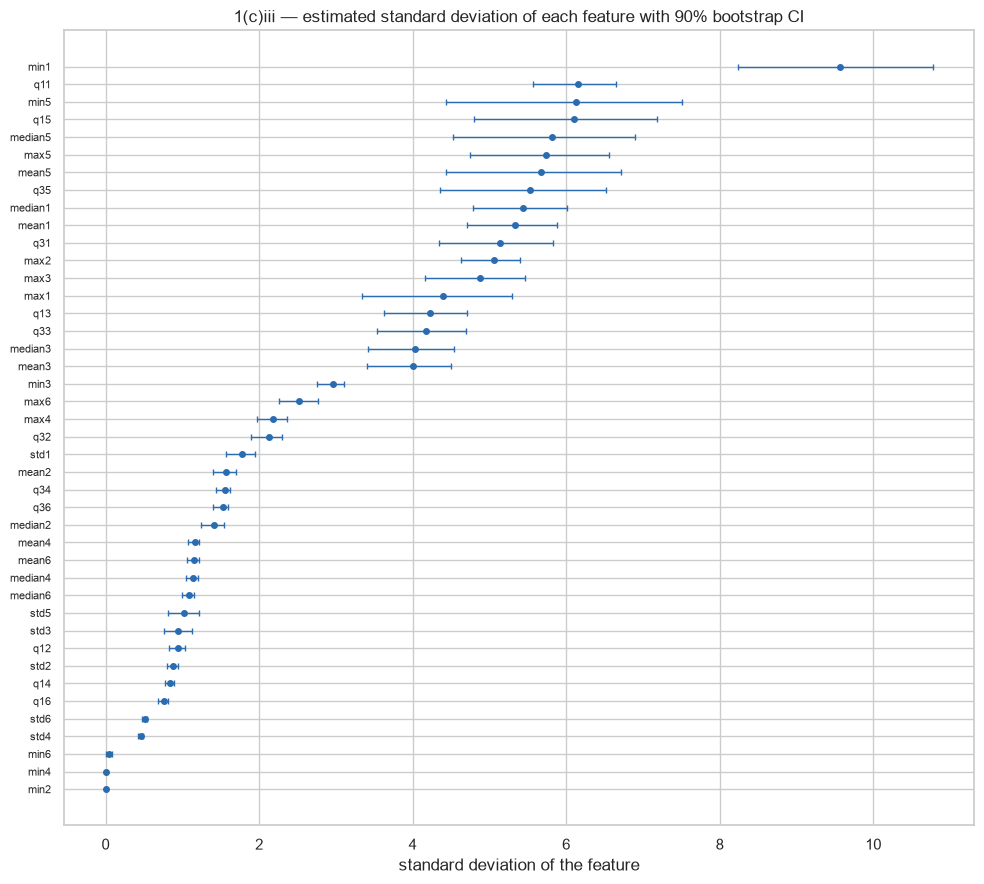

In [7]:
ordered = bootstrap_ci.sort_values("std")
fig, ax = plt.subplots(figsize=(10, 9))
ax.errorbar(ordered["std"], np.arange(len(ordered)),
            xerr=[ordered["std"] - ordered["ci_lower"], ordered["ci_upper"] - ordered["std"]],
            fmt="o", ms=4, lw=1, capsize=2, color="#2b6cb0")
ax.set_yticks(np.arange(len(ordered)))
ax.set_yticklabels(ordered.index, fontsize=8)
ax.set_xlabel("standard deviation of the feature")
ax.set_title("1(c)iii — estimated standard deviation of each feature with 90% bootstrap CI")
plt.tight_layout()
plt.show()

### 1(c)iv The three most important time-domain features

We pick **min, mean and max**, which is also the option suggested in the assignment.

Six of the seven features, min, Q1, median, mean, Q3 and max, describe the values that a signal takes.
The seventh, the standard deviation, describes how spread out the values are. The output below supports this choice:

* Median, Q1 and Q3 add little beyond the mean. Across the 88 instances, their correlation with the mean is 0.95 or higher for time series 1 and 6.
* The standard deviation is closely related to the gap between max and min, with a correlation of 0.78 for time series 1 and 0.89 for time series 6.
* Min and max show the lowest and highest values, which the mean cannot show.

So min, mean and max keep most of the information in the seven features.
For the three variance series, the mean is much higher for cycling and walking than for the other activities, as the table in 2(a)i shows.
This is what separates the still activities, bending, lying, sitting and standing, from the moving ones.

This choice has one weakness, which 2(a)i also shows.
For the three variance series, the minimum is 0 in almost every instance, so min carries almost no information there.

In [8]:
TOP_STATS = ["min", "mean", "max"]
print("selected time-domain features:", TOP_STATS)
print()
# How much the other four statistics overlap with min, mean and max (all 88 instances).
for s in (1, 6):
    mean_col = features_l1[f"mean{s}"]
    corr_with_mean = ", ".join(f"{st}{s} {mean_col.corr(features_l1[f'{st}{s}']):.3f}"
                               for st in ("q1", "median", "q3"))
    corr_std_range = features_l1[f"std{s}"].corr(features_l1[f"max{s}"] - features_l1[f"min{s}"])
    print(f"time series {s}: correlation with mean{s}: {corr_with_mean}")
    print(f"               correlation of std{s} with max{s} - min{s}: {corr_std_range:.3f}")

selected time-domain features: ['min', 'mean', 'max']

time series 1: correlation with mean1: q11 0.970, median1 0.978, q31 0.956
               correlation of std1 with max1 - min1: 0.777
time series 6: correlation with mean6: q16 0.985, median6 0.997, q36 0.997
               correlation of std6 with max6 - min6: 0.894


## 2. Time Series Classification Part 2: Binary and Multi-class Classification

### 2(a) Binary classification using logistic regression

#### 2(a)i Scatter plots of min, mean and max for time series 1, 2 and 6

Only the training set is plotted. Bending instances from `bending1` and `bending2` are in one color, and all other activities are in the other color.

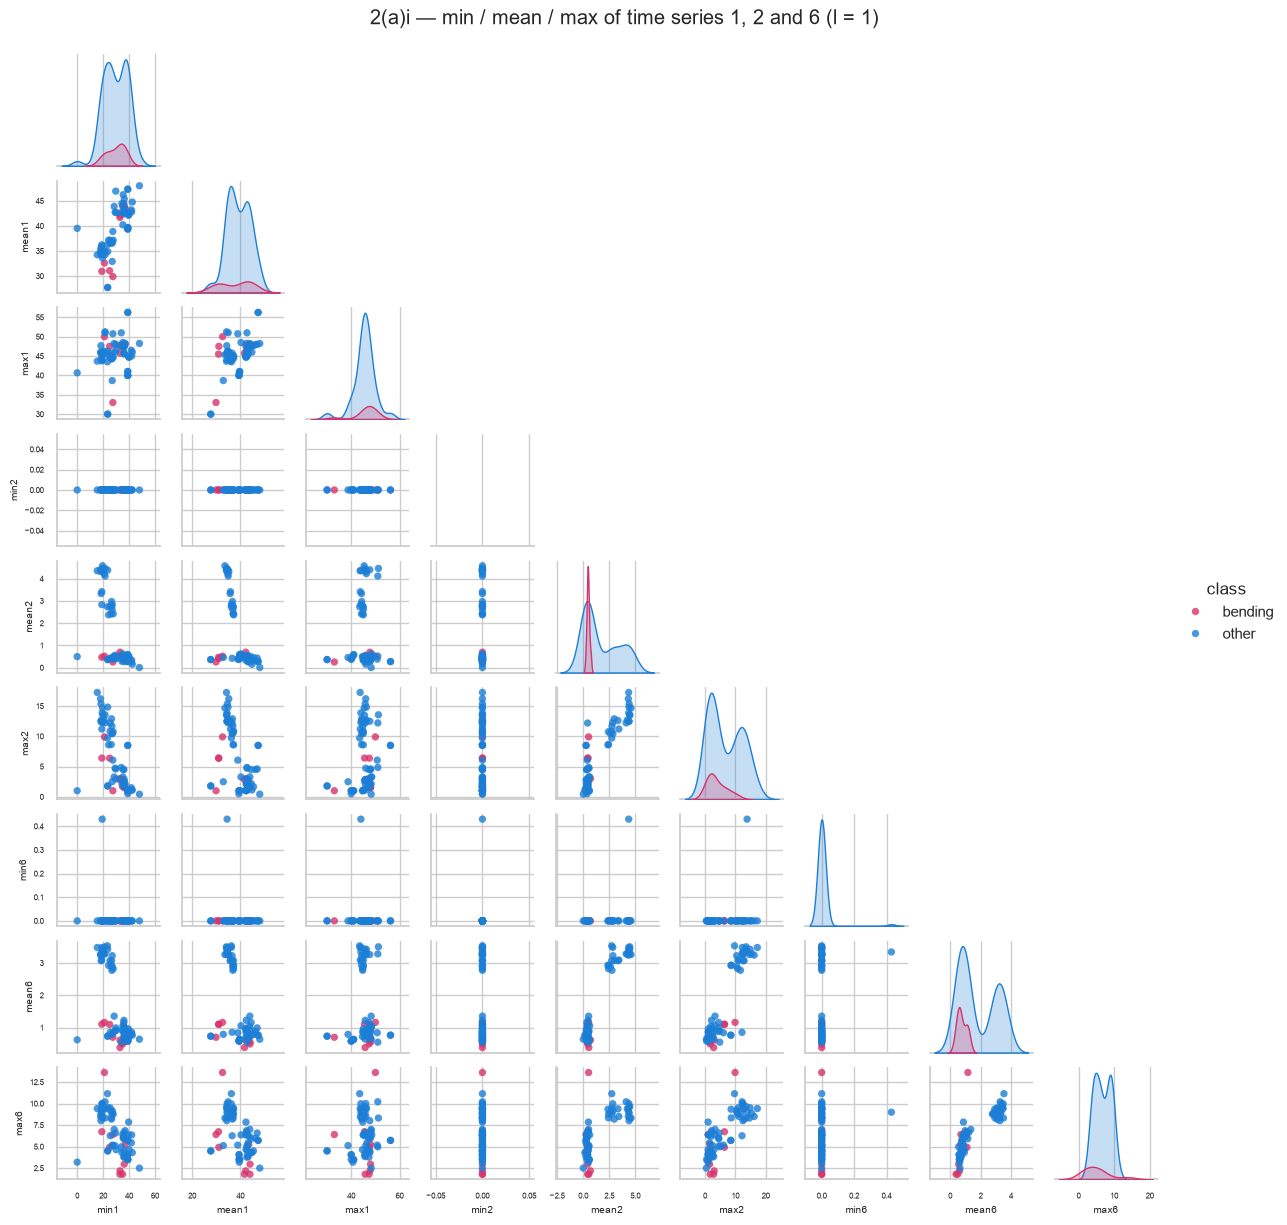

In [9]:
def scatter_matrix_for(df, stats, series_ids, title):
    # Pairwise scatter plots of the given statistics for the given time series, coloured by class.
    cols = [f"{s}{sid}" for sid in series_ids for s in stats]
    data = df.loc[df["split"] == "train", cols + ["bending"]].copy()
    data["class"] = data["bending"].map({1: "bending", 0: "other"})
    grid = sns.pairplot(data.drop(columns="bending"), hue="class", corner=True,
                        palette={"bending": "#d6336c", "other": "#1c7ed6"},
                        plot_kws=dict(s=28, alpha=0.8, edgecolor="none"), height=1.35)
    grid.figure.suptitle(title, y=1.02)
    for ax in grid.axes.flat:
        if ax is not None:
            ax.tick_params(labelsize=6)
            ax.set_xlabel(ax.get_xlabel(), fontsize=7)
            ax.set_ylabel(ax.get_ylabel(), fontsize=7)
    plt.show()


scatter_matrix_for(features_l1, TOP_STATS, [1, 2, 6],
                   "2(a)i — min / mean / max of time series 1, 2 and 6 (l = 1)")

In [10]:
def single_feature_auc(table, cols):
    # How well each feature on its own ranks bending above the other activities (training set).
    train_rows = table["split"] == "train"
    y = table.loc[train_rows, "bending"].to_numpy()
    scores = {}
    for col in cols:
        x = table.loc[train_rows, col].to_numpy()
        if np.ptp(x) == 0:
            scores[col] = np.nan  # constant column: carries no information
        else:
            a = roc_auc_score(y, x)
            scores[col] = max(a, 1 - a)
    return pd.Series(scores, name="AUC").sort_values(ascending=False)


plot_cols_1 = [f"{s}{sid}" for sid in (1, 2, 6) for s in TOP_STATS]
print("single-feature AUC on the training set (1 = perfect, 0.5 = useless):")
print(single_feature_auc(features_l1, plot_cols_1).round(3).to_string())

print()
for col in ("min2", "min4", "min6"):
    print(f"{col} is non-zero in {int((features_l1[col] != 0).sum())} of 88 instances")

train_l1 = features_l1[features_l1["split"] == "train"].copy()
train_l1["group"] = np.where(train_l1["bending"] == 1, "bending", train_l1["activity"])
print()
print("median of the three variance series by activity, training set:")
print(train_l1.groupby("group")[["mean2", "mean4", "mean6"]].median().round(2).to_string())

limit = train_l1.loc[train_l1["bending"] == 1, "mean6"].max()
print()
print(f"other training instances with mean6 at or below the largest bending value, {limit:.2f}:")
print(train_l1.loc[(train_l1["bending"] == 0) & (train_l1["mean6"] <= limit), "group"]
      .value_counts().to_string())

single-feature AUC on the training set (1 = perfect, 0.5 = useless):
mean6    0.772
max6     0.698
max1     0.649
max2     0.634
mean2    0.628
mean1    0.570
min1     0.517
min6     0.508
min2       NaN

min2 is non-zero in 0 of 88 instances
min4 is non-zero in 0 of 88 instances
min6 is non-zero in 1 of 88 instances

median of the three variance series by activity, training set:
          mean2  mean4  mean6
group                        
bending    0.43   0.82   0.68
cycling    2.75   3.00   3.07
lying      0.39   0.45   0.64
sitting    0.44   0.70   0.86
standing   0.38   0.57   0.92
walking    4.38   3.20   3.31

other training instances with mean6 at or below the largest bending value, 1.16:
group
lying       12
sitting     11
standing    11


These plots show that the three features alone do not separate the classes well.

`min2` is 0 in every instance and `min6` is 0 in all but one, because the variance channels `var_rss12` and `var_rss23` reach zero at some point in almost every recording.
So these two features carry almost no information, and the AUC of `min2` cannot even be computed.

The features of **time series 6** show the clearest pattern. Bending instances tend to have smaller `mean6` and `max6` than the other activities, with single-feature AUC of 0.77 and 0.70.
`max1`, `max2` and `mean2` are weaker, with AUC from 0.63 to 0.65. `min1` and `min6` are close to chance.

Even so, the bending points are not on their own. The table of medians shows that bending has low values on the three variance series, just like lying, sitting and standing.
Only cycling and walking have high values.
The last output confirms it: every other training instance whose `mean6` is at or below the largest bending value is a lying, sitting or standing instance.
So on these features, bending looks like the other still activities.

So these three statistics from three time series are not enough to separate bending by eye.
The almost perfect separation in 2(a)iii comes from the much larger feature set that we get by splitting the series into parts.

#### 2(a)ii The same plots after splitting each time series into two halves

Each of the 6 time series is cut in half. This gives 12 time series per instance and twice as many features.
We plot the same three statistics for both halves of time series 1, 2 and 6.

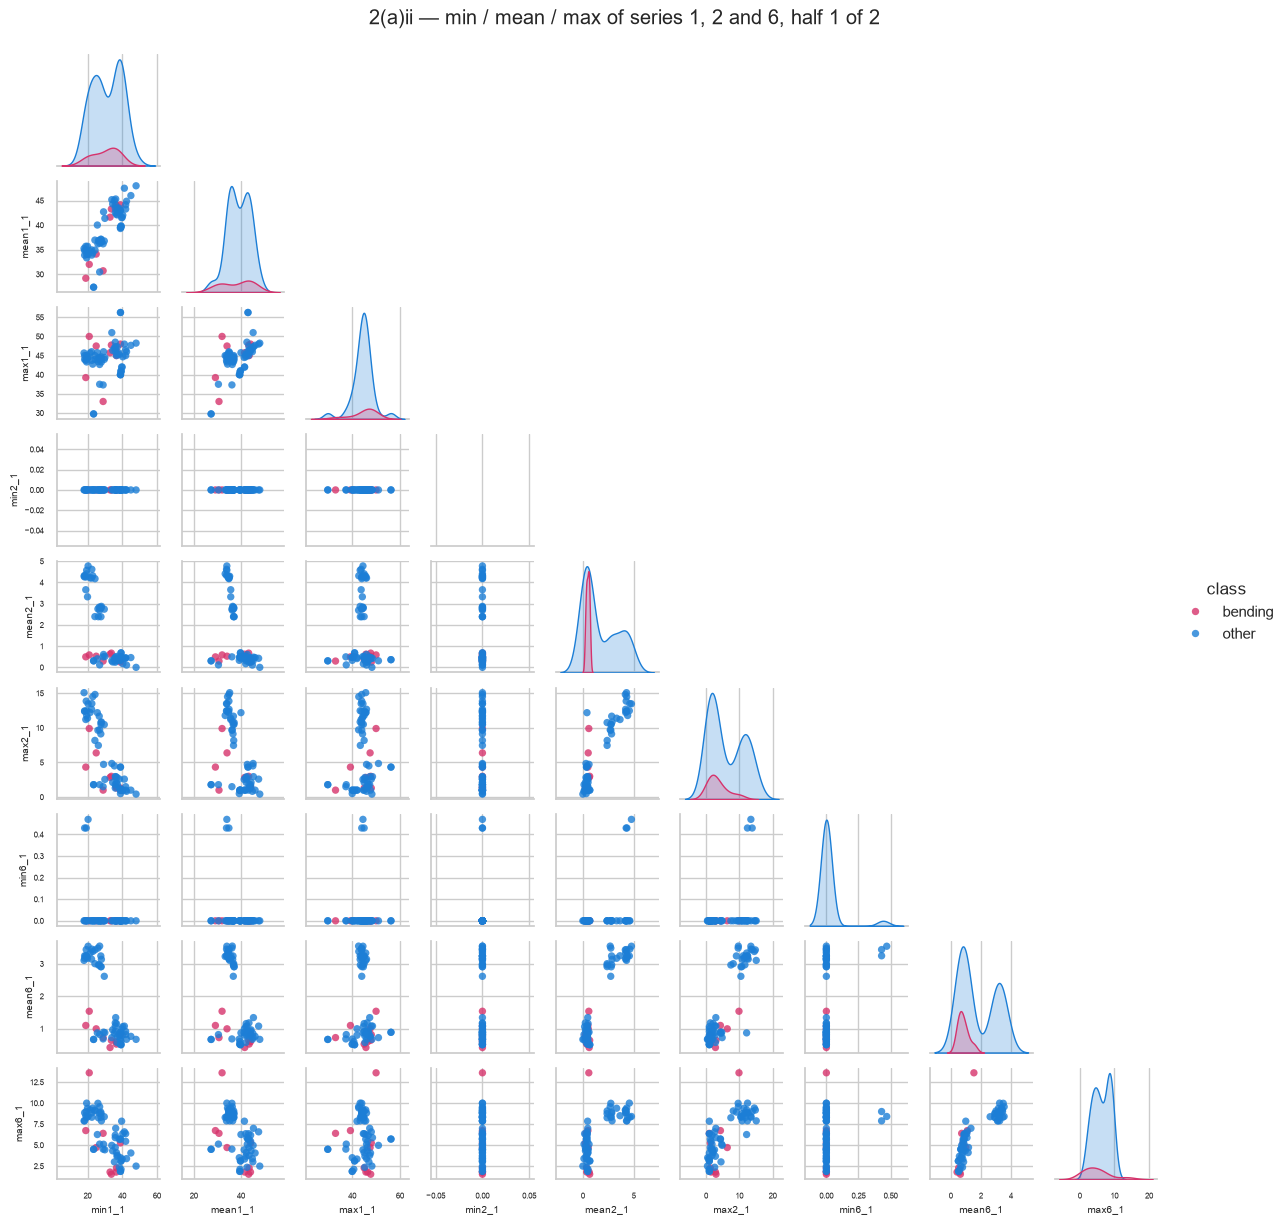

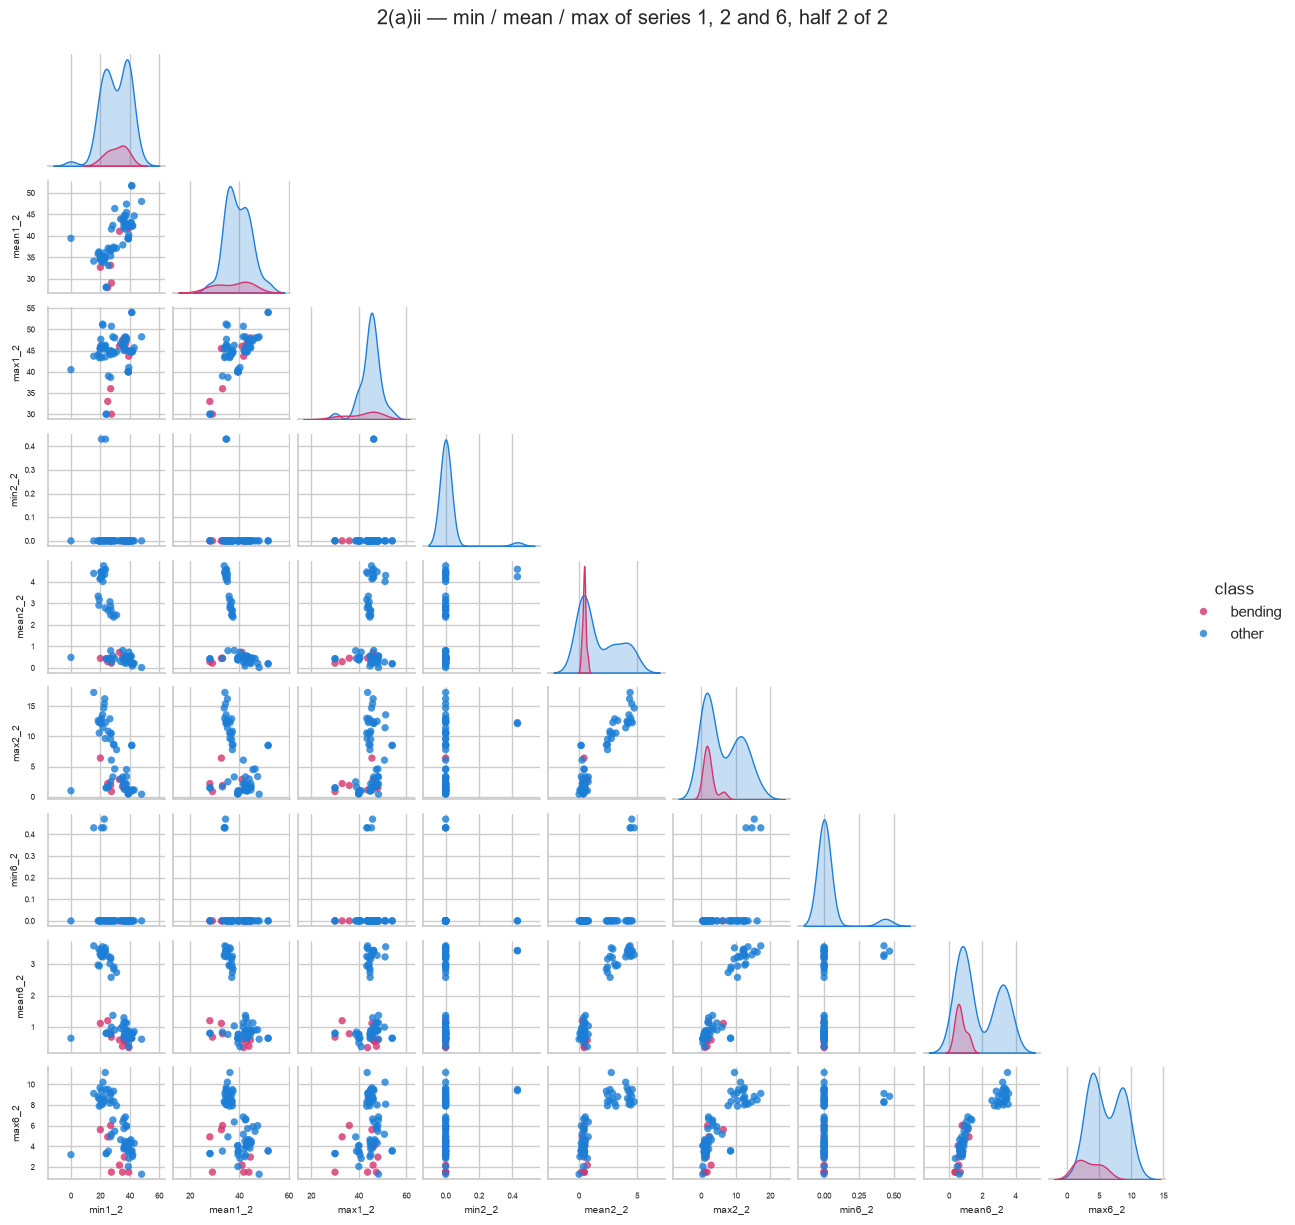

In [11]:
features_l2 = feature_table(2)
for half in (1, 2):
    cols = [f"{s}{sid}_{half}" for sid in (1, 2, 6) for s in TOP_STATS]
    data = features_l2.loc[features_l2["split"] == "train", cols + ["bending"]].copy()
    data["class"] = data["bending"].map({1: "bending", 0: "other"})
    grid = sns.pairplot(data.drop(columns="bending"), hue="class", corner=True,
                        palette={"bending": "#d6336c", "other": "#1c7ed6"},
                        plot_kws=dict(s=28, alpha=0.8, edgecolor="none"), height=1.35)
    grid.figure.suptitle(f"2(a)ii — min / mean / max of series 1, 2 and 6, half {half} of 2", y=1.02)
    for ax in grid.axes.flat:
        if ax is not None:
            ax.tick_params(labelsize=6)
            ax.set_xlabel(ax.get_xlabel(), fontsize=7)
            ax.set_ylabel(ax.get_ylabel(), fontsize=7)
    plt.show()

In [12]:
plot_cols_2 = [f"{s}{sid}_{half}" for sid in (1, 2, 6) for s in TOP_STATS for half in (1, 2)]
auc_full = single_feature_auc(features_l1, plot_cols_1)
auc_halves = single_feature_auc(features_l2, plot_cols_2)
comparison_auc = pd.DataFrame({
    "full series (l = 1)": auc_full,
    "first half": {c: auc_halves[f"{c}_1"] for c in plot_cols_1},
    "second half": {c: auc_halves[f"{c}_2"] for c in plot_cols_1},
}).sort_values("full series (l = 1)", ascending=False)
print("single-feature AUC on the training set, full series vs. the two halves:")
display(comparison_auc.round(3))

train_rows_l2 = features_l2["split"] == "train"
for col in ("min2_1", "min2_2", "min6_1", "min6_2"):
    print(f"{col} is non-zero in {int((features_l2.loc[train_rows_l2, col] != 0).sum())} of 69 training instances")

single-feature AUC on the training set, full series vs. the two halves:


,full series (l = 1),first half,second half
mean6,0.772,0.735,0.819
max6,0.698,0.678,0.790
max1,0.649,0.648,0.564
max2,0.634,0.600,0.657
mean2,0.628,0.619,0.656
mean1,0.570,0.533,0.581
min1,0.517,0.554,0.503
min6,0.508,0.525,0.533
min2,NaN,NaN,0.517


min2_1 is non-zero in 0 of 69 training instances
min2_2 is non-zero in 2 of 69 training instances
min6_1 is non-zero in 3 of 69 training instances
min6_2 is non-zero in 4 of 69 training instances


**Is there a big difference from 2(a)i?** Not in the shape of the plots.
The plots for the two halves look like the plots for the full series. Bending still has small `mean6` and `max6` and still overlaps the still activities.
`min2` and `min6` are still 0 for almost every instance, as the counts above show. No plot separates the classes cleanly.

There is one change for time series 6: its second half separates the classes better than its first half.
The single-feature AUC of `mean6` is 0.74 for the first half, 0.77 for the full series and 0.82 for the second half. For `max6` it is 0.68, 0.70 and 0.79.
This does not hold for every feature, though. `max1` does better in the first half, 0.65 against 0.56.
With only 9 bending instances, these small differences may be partly noise.

Each statistic now uses 240 samples instead of 480, so it is a bit noisier.
The number of instances stays at 69, and only the number of features doubles, from 42 to 84.
So splitting does not make the 2D picture clearer. It gives the classifier more local features to choose from, and 2(a)iii uses exactly that.

#### 2(a)iii Choosing l and p by cross-validation

Each instance is split into $l$ parts, with $l$ from 1 to 20. This gives $42l$ candidate features.
Recursive feature elimination, or RFE, is the backward selection method suggested in the assignment. It keeps $p$ of the features, and we try $p$ up to 30.
To save time, RFE removes about 2.5% of the features per step until 30 are left, and then removes one feature at a time.
We choose $l$ and $p$ together with 5-fold cross-validation.
Several pairs share the best score, so we break ties by taking the smallest $p$ and then the smallest $l$. This gives the simplest final model.

**The wrong way.** Run RFE once on the whole training set to choose the $p$ best features. Then run cross-validation on a logistic regression that uses only those features.
This is wrong because the feature selection has already seen every fold. Each validation fold helped choose the features that it is later used to test.
The result is too optimistic. With 840 features and only 69 instances, some features can separate the classes just by chance, and this method would report them as a success.

**The right way.** Treat feature selection as part of model fitting. In each of the 5 folds, fit the scaler and RFE on the training part of that fold only.
Then fit the model and test it on the held-out part. Only $l$ and $p$ are shared across folds.
The code below does this: `StandardScaler` and `RFE` are fit only on the training rows of each fold.

**Class imbalance and stratified cross-validation.** The training set has 9 bending and 60 other instances.
With normal 5-fold cross-validation, a fold could end up with no bending instance at all. Its accuracy would then mean little, and the model might fail to fit.
Stratified cross-validation splits each class separately, so every fold keeps about the same class ratio as the full training set.
Here that is about 2 bending and 12 other instances per fold. We use `StratifiedKFold` everywhere.

In [13]:
def base_logreg():
    # Logistic regression with the L2 penalty effectively switched off (C -> inf).
    # max_iter is kept moderate so that separable folds stop before the coefficients blow up.
    return LogisticRegression(penalty="l2", C=1e6, solver="liblinear", max_iter=200,
                              random_state=RANDOM_STATE)


def rfe_ranking(X, y, n_fine=30):
    # Full backward-elimination ordering of the columns of X (best feature first).
    # A coarse, multi-feature-per-step RFE trims the candidate set down to n_fine, then a
    # step-1 RFE ranks those finely; this keeps the ordering exact where p is actually chosen.
    n = X.shape[1]
    n_fine = min(n_fine, n)
    if n > n_fine:
        coarse = RFE(base_logreg(), n_features_to_select=n_fine, step=max(1, n // 40)).fit(X, y)
        kept = np.flatnonzero(coarse.support_)
        dropped = np.flatnonzero(~coarse.support_)
        dropped = dropped[np.argsort(coarse.ranking_[dropped], kind="stable")]
    else:
        kept, dropped = np.arange(n), np.array([], dtype=int)
    fine = RFE(base_logreg(), n_features_to_select=1, step=1).fit(X[:, kept], y)
    kept = kept[np.argsort(fine.ranking_, kind="stable")]
    return np.concatenate([kept, dropped])

In [14]:
L_GRID = list(range(1, 21))
P_GRID = [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 12, 15, 20, 25, 30]

# Feature tables for every l, computed once and reused by 2(a), 2(b) and 2(c).
FEATURES = {l: feature_table(l) for l in L_GRID}
y_all = meta["bending"].to_numpy()
y_train, y_test = y_all[is_train], y_all[~is_train]


def split_matrices(l):
    # Raw (unstandardized) train/test design matrices and the feature names for a given l.
    table = FEATURES[l]
    cols = table.columns[META_COLS:]
    return (table.loc[is_train, cols].to_numpy(),
            table.loc[~is_train, cols].to_numpy(),
            np.array(cols))


print("feature tables built for l =", L_GRID[0], "...", L_GRID[-1])
print("largest design matrix:", split_matrices(20)[0].shape)

feature tables built for l = 1 ... 20
largest design matrix: (69, 840)


In [15]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
records = []

for l in L_GRID:
    X_tr, _, _ = split_matrices(l)
    scores = {p: [] for p in P_GRID if p <= X_tr.shape[1]}
    for fit_idx, val_idx in cv.split(X_tr, y_train):
        # Everything below is fitted on the fold's training part only (the right way).
        scaler = StandardScaler().fit(X_tr[fit_idx])
        X_fit, X_val = scaler.transform(X_tr[fit_idx]), scaler.transform(X_tr[val_idx])
        ranking = rfe_ranking(X_fit, y_train[fit_idx])
        for p in scores:
            keep = ranking[:p]
            model = base_logreg().fit(X_fit[:, keep], y_train[fit_idx])
            scores[p].append(model.score(X_val[:, keep], y_train[val_idx]))
    for p, vals in scores.items():
        records.append({"l": l, "p": p, "cv_accuracy": float(np.mean(vals))})

cv_results = pd.DataFrame(records)
# Ties are broken in favour of the simplest final model: fewest selected features p, then
# the smallest number of chunks l.
best = cv_results.sort_values(["cv_accuracy", "p", "l"], ascending=[False, True, True]).iloc[0]
BEST_L, BEST_P = int(best["l"]), int(best["p"])
print(f"best (l, p) = ({BEST_L}, {BEST_P}) with 5-fold CV accuracy {best['cv_accuracy']:.4f}")
cv_results.pivot(index="l", columns="p", values="cv_accuracy").round(3)

best (l, p) = (20, 2) with 5-fold CV accuracy 0.9857


p,1,2,3,4,5,6,7,8,9,10,12,15,20,25,30
l,,,,,,,,,,,,,,,
1,0.899,0.885,0.943,0.929,0.914,0.943,0.957,0.957,0.957,0.927,0.956,0.957,0.957,0.957,0.957
2,0.899,0.942,0.957,0.957,0.943,0.957,0.957,0.942,0.942,0.913,0.913,0.927,0.927,0.927,0.913
3,0.927,0.856,0.899,0.929,0.927,0.929,0.929,0.929,0.943,0.943,0.929,0.914,0.929,0.929,0.914
4,0.943,0.913,0.899,0.929,0.943,0.957,0.943,0.971,0.943,0.943,0.943,0.943,0.929,0.929,0.943
5,0.943,0.899,0.913,0.929,0.929,0.927,0.942,0.927,0.913,0.927,0.927,0.942,0.899,0.942,0.885
6,0.900,0.927,0.943,0.943,0.986,0.957,0.971,0.957,0.943,0.957,0.943,0.943,0.943,0.943,0.957
7,0.913,0.899,0.885,0.899,0.914,0.914,0.943,0.943,0.929,0.929,0.913,0.927,0.927,0.885,0.885
8,0.900,0.914,0.957,0.927,0.929,0.914,0.900,0.886,0.900,0.914,0.914,0.929,0.929,0.929,0.929
9,0.943,0.929,0.913,0.942,0.929,0.929,0.898,0.898,0.898,0.884,0.927,0.913,0.899,0.885,0.899


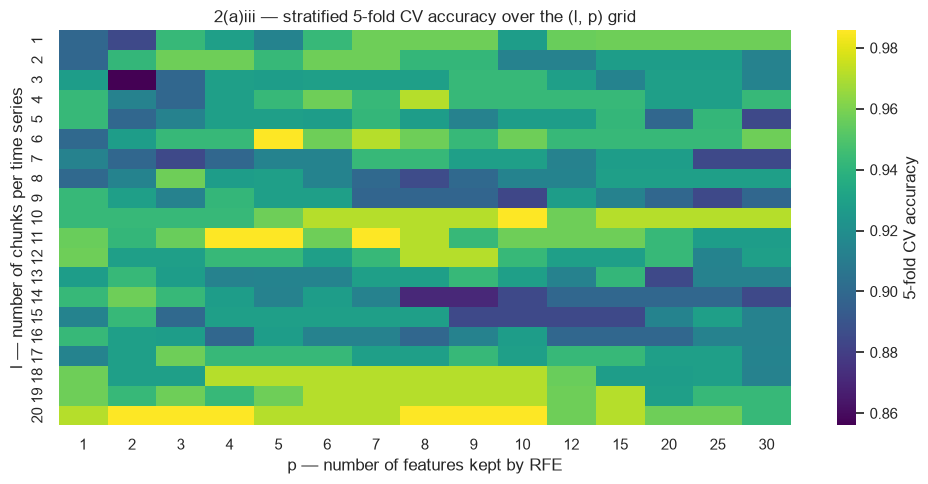

In [16]:
fig, ax = plt.subplots(figsize=(10, 5))
sns.heatmap(cv_results.pivot(index="l", columns="p", values="cv_accuracy"),
            cmap="viridis", annot=False, cbar_kws={"label": "5-fold CV accuracy"}, ax=ax)
ax.set_title("2(a)iii — stratified 5-fold CV accuracy over the (l, p) grid")
ax.set_xlabel("p — number of features kept by RFE")
ax.set_ylabel("l — number of chunks per time series")
plt.tight_layout()
plt.show()

#### 2(a)iv Final model on the training set: confusion matrix, ROC, AUC, coefficients and p-values

We now refit on the whole training set with the chosen $l$ and $p$.
We standardize the features, run RFE once to pick $p$ features, and fit the logistic regression on them.

In [17]:
X_train_raw, X_test_raw, feature_names = split_matrices(BEST_L)
scaler = StandardScaler().fit(X_train_raw)
X_train, X_test = scaler.transform(X_train_raw), scaler.transform(X_test_raw)

selected = rfe_ranking(X_train, y_train)[:BEST_P]
SELECTED_NAMES = list(feature_names[selected])
final_model = base_logreg().fit(X_train[:, selected], y_train)

print(f"l = {BEST_L}, p = {BEST_P}")
print("features selected by RFE:", SELECTED_NAMES)

l = 20, p = 2
features selected by RFE: ['q15_3', 'std3_16']


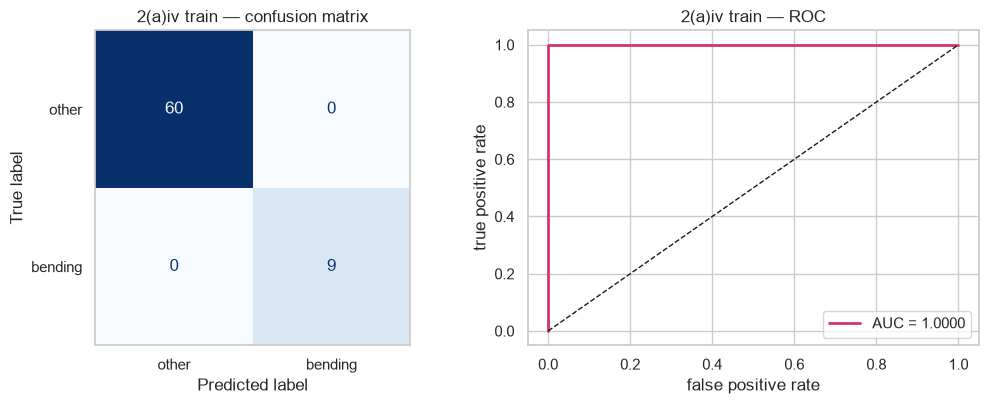

2(a)iv train: accuracy = 1.0000, AUC = 1.0000
              precision    recall  f1-score   support

       other       1.00      1.00      1.00        60
     bending       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



In [18]:
def report_binary(y_true, scores, y_pred, title):
    # Confusion matrix + ROC curve with AUC, for a binary classifier.
    cm = confusion_matrix(y_true, y_pred)
    fpr, tpr, _ = roc_curve(y_true, scores)
    area = auc(fpr, tpr)
    fig, axes = plt.subplots(1, 2, figsize=(10.5, 4.2))
    ConfusionMatrixDisplay(cm, display_labels=["other", "bending"]).plot(
        ax=axes[0], cmap="Blues", colorbar=False)
    axes[0].set_title(f"{title} — confusion matrix")
    axes[0].grid(False)
    axes[1].plot(fpr, tpr, lw=2, color="#d6336c", label=f"AUC = {area:.4f}")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set_xlabel("false positive rate")
    axes[1].set_ylabel("true positive rate")
    axes[1].set_title(f"{title} — ROC")
    axes[1].legend(loc="lower right")
    plt.tight_layout()
    plt.show()
    acc = (y_true == y_pred).mean()
    print(f"{title}: accuracy = {acc:.4f}, AUC = {area:.4f}")
    print(classification_report(y_true, y_pred, target_names=["other", "bending"], zero_division=0))
    return acc, area


train_scores = final_model.decision_function(X_train[:, selected])
train_acc, train_auc = report_binary(y_train, train_scores,
                                     final_model.predict(X_train[:, selected]), "2(a)iv train")

In [19]:
# Coefficients from scikit-learn and the p-values from the equivalent statsmodels fit.
design = sm.add_constant(X_train[:, selected], has_constant="add")
sm_fit = sm.Logit(y_train, design).fit(method="newton", maxiter=100, disp=0)

coef_table = pd.DataFrame({
    "feature": ["intercept"] + SELECTED_NAMES,
    "beta_sklearn": np.concatenate([final_model.intercept_, final_model.coef_.ravel()]),
    "beta_statsmodels": sm_fit.params,
    "std_err": sm_fit.bse,
    "z": sm_fit.tvalues,
    "p_value": sm_fit.pvalues,
})
print("logistic regression parameters (features are standardized)")
coef_table.round(4)

logistic regression parameters (features are standardized)


,feature,beta_sklearn,beta_statsmodels,std_err,z,p_value
0,intercept,-29.3956,-81.3309,131395.6423,-0.0006,0.9995
1,q15_3,34.0452,105.4333,145411.3850,0.0007,0.9994
2,std3_16,-12.2734,-30.6002,121371.9220,-0.0003,0.9998


The table shows the coefficients from scikit-learn, which makes the predictions, and from statsmodels, which gives the standard errors and p-values.
The two libraries give very different coefficients for the same data and the same features, for example 34.0 and 105.4 for `q15_3`.
The standard errors are huge, so every p-value is close to 1.

This does not mean the features are useless. It is a sign of **perfect separation**, which is discussed in 2(a)vi.
When the two classes can be split exactly, the likelihood keeps going up as the coefficients get larger.
So the maximum likelihood estimate does not exist, and the coefficients, standard errors and p-values cannot be trusted.

#### 2(a)v Performance on the test set

The test instances are split into the same $l$ parts and the same features are extracted.
We apply the scaler from the training set and use the same $p$ columns.

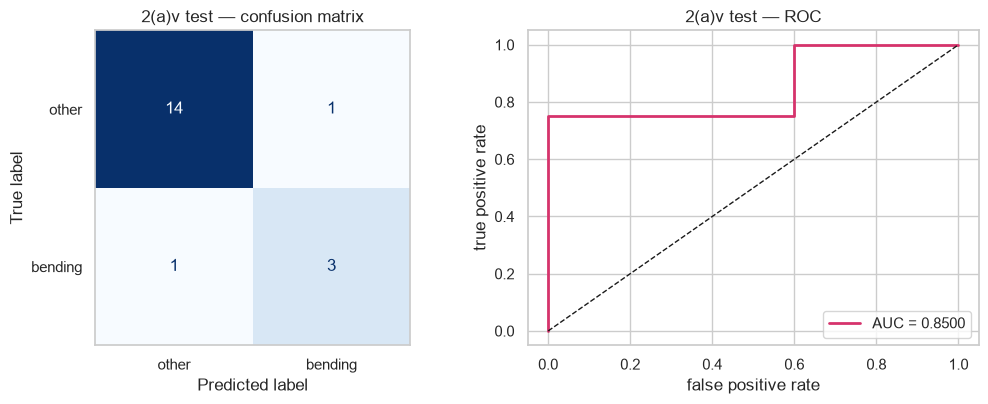

2(a)v test: accuracy = 0.8947, AUC = 0.8500
              precision    recall  f1-score   support

       other       0.93      0.93      0.93        15
     bending       0.75      0.75      0.75         4

    accuracy                           0.89        19
   macro avg       0.84      0.84      0.84        19
weighted avg       0.89      0.89      0.89        19



,accuracy,AUC
5-fold CV (training set),0.9857,NaN
training set (refit),1.0000,1.00
test set,0.8947,0.85


In [20]:
test_scores = final_model.decision_function(X_test[:, selected])
test_acc, test_auc = report_binary(y_test, test_scores,
                                   final_model.predict(X_test[:, selected]), "2(a)v test")

summary_2a = pd.DataFrame({
    "accuracy": [best["cv_accuracy"], train_acc, test_acc],
    "AUC": [np.nan, train_auc, test_auc],
}, index=["5-fold CV (training set)", "training set (refit)", "test set"])
summary_2a.round(4)

**Comparison.** The cross-validation accuracy is 0.986 and the test accuracy is 0.895.

Both numbers are uncertain. The cross-validation number was computed the right way, with feature selection redone inside every fold.
But we picked $l$ and $p$ because they had the best score out of 300 pairs, and the best of many noisy scores tends to be lucky. So it is probably a bit too high.
The test accuracy is the only clean estimate, but it is based on only 19 instances, so each mistake changes it by about 5 percentage points.
The model makes 2 mistakes on the test set: it misses one bending instance and gives one false alarm.

The training accuracy is 100%, but this tells us nothing because the classes are separable.

#### 2(a)vi Are the classes separated well enough to make logistic regression unstable?

**Yes.** The checks below all point the same way.

In [21]:
print(f"training accuracy          : {train_acc:.4f}")
print(f"training AUC               : {train_auc:.4f}")
print(f"largest |beta|             : {np.abs(final_model.coef_).max():.1f}")
print(f"largest standard error     : {sm_fit.bse.max():.1f}")
print(f"smallest p-value           : {sm_fit.pvalues.min():.4f}")
probs = final_model.predict_proba(X_train[:, selected])[:, 1]
print(f"fitted probabilities within 1e-3 of 0 or 1: {int(np.sum((probs < 1e-3) | (probs > 1 - 1e-3)))}/{len(probs)}")
print(f"margin between classes (standardized scores): "
      f"{train_scores[y_train == 1].min() - train_scores[y_train == 0].max():.2f}")

training accuracy          : 1.0000
training AUC               : 1.0000
largest |beta|             : 34.0
largest standard error     : 145411.4
smallest p-value           : 0.9994
fitted probabilities within 1e-3 of 0 or 1: 68/69
margin between classes (standardized scores): 13.59


The training set is classified perfectly, and the AUC is exactly 1.
There is a clear gap of 13.6 between the lowest bending score and the highest score of the other class.
68 of the 69 fitted probabilities are within 0.001 of 0 or 1.

The coefficients are not realistic. The features are standardized, so a coefficient of 34 on `q15_3` would mean that one standard deviation multiplies the odds of bending by about $e^{34}$, which is more than $10^{14}$.
The statsmodels standard errors are all larger than 100,000.

This is complete separation, and nothing in the data stops the coefficients from growing.
The scikit-learn coefficients stay finite only because of its very weak ridge penalty with $C = 10^6$ and its iteration limit.
The statsmodels fit has no penalty, so its coefficients depend on when its optimizer stops. This is why the two libraries disagree so much.

In practice, this means the sizes of the coefficients and all the p-values are not meaningful here. The model is unstable even though its predictions are good.
The fixes are the ones used later in this homework: add a penalty to the coefficients, as in the L1 model of 2(b), or stop the optimizer early, as the assignment suggests.

#### 2(a)vii Class imbalance and case-control sampling

Yes, the classes are imbalanced. The training set has 60 other instances and only 9 bending instances, a ratio of about 6.7 to 1. The test set has 15 and 4.
The confusion matrices show why this matters. On the test set, missing one of the 4 bending instances lowers the bending recall by 25 percentage points,
but lowers the overall accuracy by only about 5.

**Case-control sampling.** We keep all 9 cases, which are the bending instances, and randomly pick 9 controls from the 60 other instances.
This gives a balanced sample of 18. In theory, a logistic regression fit on such a sample still gives valid slopes.
Only the intercept is off, because we changed the class ratio on purpose.
If cases are kept with probability $\tau_1$ and controls with probability $\tau_0$, the fix is:

$$\hat\beta_0^{\text{corrected}} = \hat\beta_0^{\text{sample}} - \log\frac{\tau_1}{\tau_0}$$

Here $\tau_1 = 1$ because every case is kept, and $\tau_0 = 9/60$.

In [22]:
cc_rng = np.random.default_rng(RANDOM_STATE)
case_idx = np.flatnonzero(y_train == 1)
control_idx = np.flatnonzero(y_train == 0)
sampled_controls = cc_rng.choice(control_idx, size=case_idx.size, replace=False)
cc_idx = np.concatenate([case_idx, sampled_controls])

cc_model = base_logreg().fit(X_train[np.ix_(cc_idx, selected)], y_train[cc_idx])
tau1, tau0 = 1.0, case_idx.size / control_idx.size
offset = np.log(tau1 / tau0)
beta0_corrected = cc_model.intercept_[0] - offset

print(f"case-control sample: {case_idx.size} cases + {sampled_controls.size} controls")
print(f"tau1 = {tau1:.3f}, tau0 = {tau0:.3f}, log(tau1/tau0) = {offset:.4f}")
print(f"intercept on the sample : {cc_model.intercept_[0]:.4f}")
print(f"intercept corrected     : {beta0_corrected:.4f}")
pd.DataFrame({"feature": ["intercept"] + SELECTED_NAMES,
              "beta_case_control": np.concatenate([[beta0_corrected], cc_model.coef_.ravel()])}).round(4)

case-control sample: 9 cases + 9 controls
tau1 = 1.000, tau0 = 0.150, log(tau1/tau0) = 1.8971
intercept on the sample : -15.9838
intercept corrected     : -17.8809


,feature,beta_case_control
0,intercept,-17.8809
1,q15_3,15.3967
2,std3_16,-11.0337


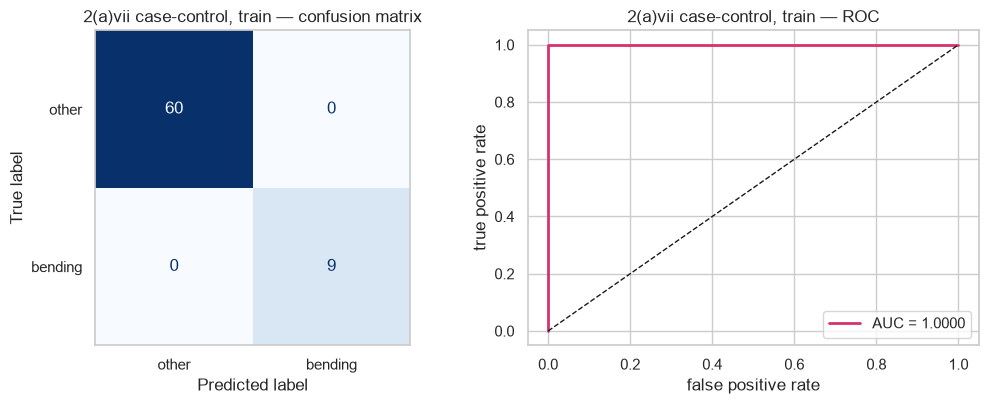

2(a)vii case-control, train: accuracy = 1.0000, AUC = 1.0000
              precision    recall  f1-score   support

       other       1.00      1.00      1.00        60
     bending       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



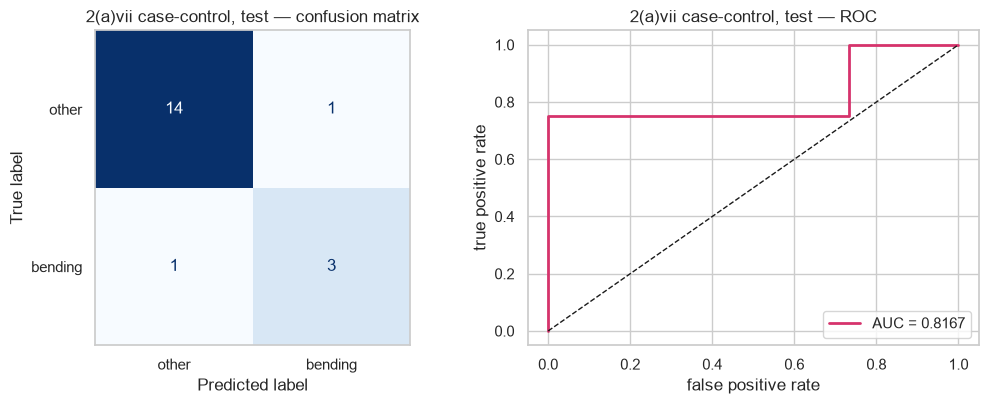

2(a)vii case-control, test: accuracy = 0.8947, AUC = 0.8167
              precision    recall  f1-score   support

       other       0.93      0.93      0.93        15
     bending       0.75      0.75      0.75         4

    accuracy                           0.89        19
   macro avg       0.84      0.84      0.84        19
weighted avg       0.89      0.89      0.89        19



,accuracy,AUC
"full sample, train",1.0000,1.0000
"full sample, test",0.8947,0.8500
"case-control, train",1.0000,1.0000
"case-control, test",0.8947,0.8167


In [23]:
def cc_scores(X):
    return X[:, selected] @ cc_model.coef_.ravel() + beta0_corrected


cc_train_scores, cc_test_scores = cc_scores(X_train), cc_scores(X_test)
cc_train_acc, cc_train_auc = report_binary(y_train, cc_train_scores,
                                           (cc_train_scores > 0).astype(int),
                                           "2(a)vii case-control, train")
cc_test_acc, cc_test_auc = report_binary(y_test, cc_test_scores,
                                         (cc_test_scores > 0).astype(int),
                                         "2(a)vii case-control, test")
pd.DataFrame({
    "accuracy": [train_acc, test_acc, cc_train_acc, cc_test_acc],
    "AUC": [train_auc, test_auc, cc_train_auc, cc_test_auc],
}, index=["full sample, train", "full sample, test",
          "case-control, train", "case-control, test"]).round(4)

The case-control model is fit on only 18 instances, about a quarter of the data. It still gets the same training and test accuracy as the full model.
On the test set it also misses one bending instance and gives one false alarm. Its test AUC is a little lower, 0.82 against 0.85.

Its slopes, 15.4 and $-11.0$, are quite different from the full model's 34.0 and $-12.3$. This does not contradict the theory above.
The classes are separable here, so as 2(a)vi showed, the size of the slopes is not stable in either model.

The main effect of the fix is on the intercept. Without it, the model would act as if bending happened half the time, and its predicted probabilities of bending would be too high.
Subtracting $\log \frac{\tau_1}{\tau_0} \approx 1.90$ brings back the class ratio of the training data.
This fix does not change the ROC curve or the AUC. Those only depend on the order of the scores, and moving every score by the same amount keeps the order.

### 2(b) Binary classification using L1-penalized logistic regression

#### 2(b)i Choosing l and λ by cross-validation

Instead of choosing features with p-values or RFE, the L1 penalty chooses them itself. It pushes some coefficients to exactly zero.
We tune two settings together with the same stratified 5-fold cross-validation: $l$ from 1 to 20, and the budget $C = 1/\lambda$ from 0.001 to 1000.
The scaler is inside the pipeline, so it is refit on the training part of each fold. This is the right way from 2(a)iii again.

In [24]:
C_GRID = np.logspace(-3, 3, 13)
l1_records = []

for l in L_GRID:
    X_tr, _, _ = split_matrices(l)
    for C in C_GRID:
        pipe = make_pipeline(
            StandardScaler(),
            LogisticRegression(penalty="l1", C=C, solver="liblinear", max_iter=5000,
                               random_state=RANDOM_STATE))
        score = cross_val_score(pipe, X_tr, y_train, cv=cv, scoring="accuracy").mean()
        l1_records.append({"l": l, "C": C, "cv_accuracy": score})

l1_results = pd.DataFrame(l1_records)
best_l1 = l1_results.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).iloc[0]
BEST_L_L1, BEST_C_L1 = int(best_l1["l"]), float(best_l1["C"])
print(f"best (l, C) = ({BEST_L_L1}, {BEST_C_L1:.4g})  ->  lambda = {1 / BEST_C_L1:.4g}, "
      f"CV accuracy = {best_l1['cv_accuracy']:.4f}")
l1_results.pivot(index="l", columns="C", values="cv_accuracy").round(3)

best (l, C) = (19, 1)  ->  lambda = 1, CV accuracy = 0.9857


C,0.001000,0.003162,0.010000,0.031623,0.100000,0.316228,1.000000,3.162278,10.000000,31.622777,100.000000,316.227766,1000.000000
l,,,,,,,,,,,,,
1,0.87,0.87,0.87,0.87,0.885,0.956,0.957,0.957,0.957,0.957,0.957,0.957,0.957
2,0.87,0.87,0.87,0.87,0.885,0.927,0.957,0.943,0.943,0.943,0.957,0.957,0.942
3,0.87,0.87,0.87,0.87,0.870,0.971,0.957,0.943,0.943,0.943,0.943,0.929,0.929
4,0.87,0.87,0.87,0.87,0.885,0.942,0.957,0.943,0.943,0.929,0.929,0.929,0.929
5,0.87,0.87,0.87,0.87,0.899,0.913,0.913,0.942,0.927,0.927,0.927,0.899,0.899
6,0.87,0.87,0.87,0.87,0.885,0.927,0.943,0.957,0.943,0.957,0.957,0.957,0.943
7,0.87,0.87,0.87,0.87,0.899,0.927,0.927,0.927,0.927,0.927,0.927,0.927,0.913
8,0.87,0.87,0.87,0.87,0.885,0.913,0.929,0.929,0.929,0.914,0.929,0.929,0.943
9,0.87,0.87,0.87,0.87,0.913,0.927,0.927,0.927,0.927,0.913,0.899,0.899,0.913


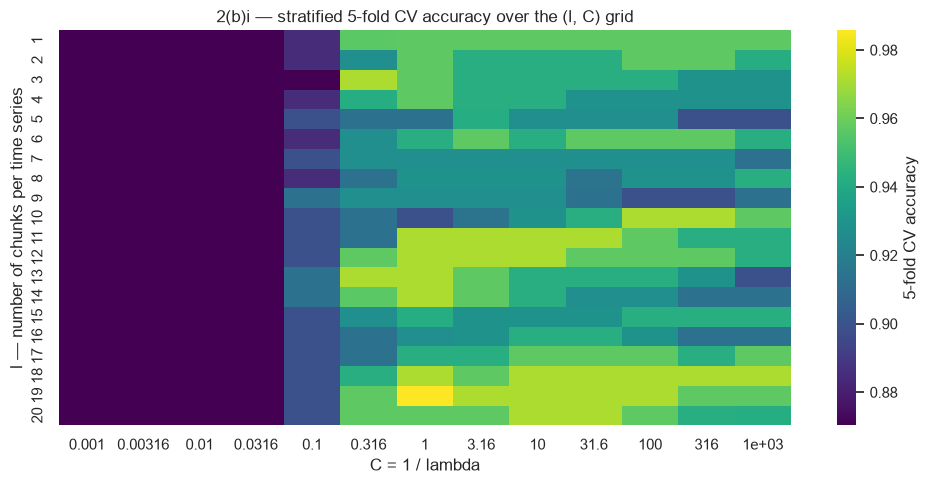

In [25]:
fig, ax = plt.subplots(figsize=(10, 5))
pivot = l1_results.pivot(index="l", columns="C", values="cv_accuracy")
sns.heatmap(pivot, cmap="viridis", cbar_kws={"label": "5-fold CV accuracy"},
            xticklabels=[f"{c:.3g}" for c in pivot.columns], ax=ax)
ax.set_title("2(b)i — stratified 5-fold CV accuracy over the (l, C) grid")
ax.set_xlabel("C = 1 / lambda")
ax.set_ylabel("l — number of chunks per time series")
plt.tight_layout()
plt.show()

features with a non-zero coefficient: 10 of 798


,feature,beta
2,q15_3,2.1256
7,min5_17,0.6200
4,max1_11,-0.5720
6,std6_15,-0.2159
9,max6_18,-0.1190
8,std5_18,-0.0753
0,min5_2,0.0544
5,std4_14,-0.0519
1,min5_3,0.0357
3,max5_5,0.0112


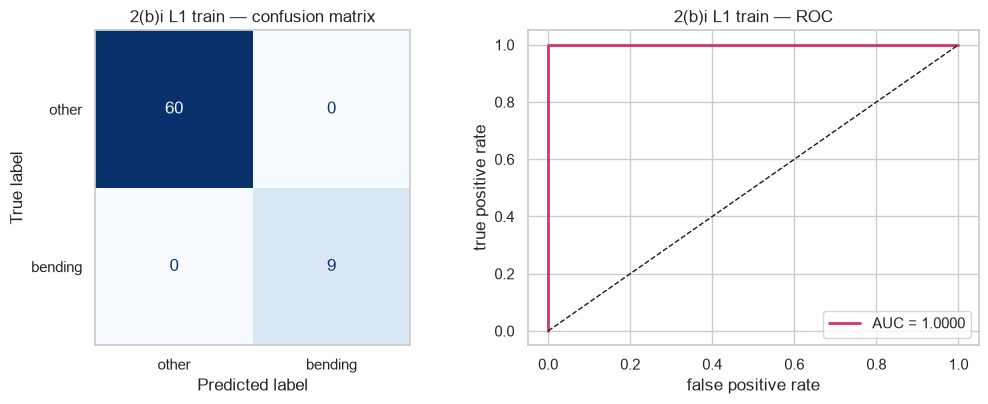

2(b)i L1 train: accuracy = 1.0000, AUC = 1.0000
              precision    recall  f1-score   support

       other       1.00      1.00      1.00        60
     bending       1.00      1.00      1.00         9

    accuracy                           1.00        69
   macro avg       1.00      1.00      1.00        69
weighted avg       1.00      1.00      1.00        69



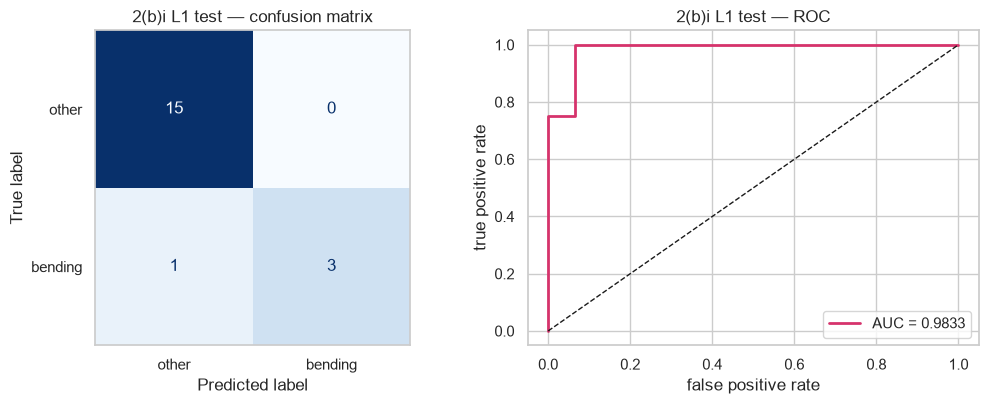

2(b)i L1 test: accuracy = 0.9474, AUC = 0.9833
              precision    recall  f1-score   support

       other       0.94      1.00      0.97        15
     bending       1.00      0.75      0.86         4

    accuracy                           0.95        19
   macro avg       0.97      0.88      0.91        19
weighted avg       0.95      0.95      0.94        19



In [26]:
X_train_raw_l1, X_test_raw_l1, names_l1 = split_matrices(BEST_L_L1)
scaler_l1 = StandardScaler().fit(X_train_raw_l1)
Xtr_l1, Xte_l1 = scaler_l1.transform(X_train_raw_l1), scaler_l1.transform(X_test_raw_l1)

l1_model = LogisticRegression(penalty="l1", C=BEST_C_L1, solver="liblinear",
                              max_iter=5000, random_state=RANDOM_STATE).fit(Xtr_l1, y_train)
nonzero = np.flatnonzero(l1_model.coef_.ravel())
print(f"features with a non-zero coefficient: {nonzero.size} of {Xtr_l1.shape[1]}")
display(pd.DataFrame({"feature": names_l1[nonzero],
                      "beta": l1_model.coef_.ravel()[nonzero]})
        .sort_values("beta", key=np.abs, ascending=False).round(4).head(20))

l1_train_acc, l1_train_auc = report_binary(
    y_train, l1_model.decision_function(Xtr_l1), l1_model.predict(Xtr_l1), "2(b)i L1 train")
l1_test_acc, l1_test_auc = report_binary(
    y_test, l1_model.decision_function(Xte_l1), l1_model.predict(Xte_l1), "2(b)i L1 test")

#### 2(b)ii L1 regularization versus variable selection with p-values and RFE

In [27]:
pd.DataFrame({
    "l": [BEST_L, BEST_L_L1],
    "selected features": [BEST_P, int(nonzero.size)],
    "CV accuracy": [best["cv_accuracy"], best_l1["cv_accuracy"]],
    "train accuracy": [train_acc, l1_train_acc],
    "test accuracy": [test_acc, l1_test_acc],
    "test AUC": [test_auc, l1_test_auc],
}, index=["2(a) RFE / p-values", "2(b) L1-penalized"]).round(4)

,l,selected features,CV accuracy,train accuracy,test accuracy,test AUC
2(a) RFE / p-values,20,2,0.9857,1.0,0.8947,0.8500
2(b) L1-penalized,19,10,0.9857,1.0,0.9474,0.9833


**Which one performs better?** The two are very close on this data. They have the same cross-validation accuracy, 0.986.
On the 19 test instances, the L1 model makes 1 mistake and the RFE model makes 2. With so few test instances, one mistake is not strong evidence.
The test AUC also favors L1, 0.98 against 0.85.

The L1 model is also more reliable. Its penalty keeps the coefficients finite even when the classes are separable, so it avoids the problem we saw in 2(a)vi.
Its largest coefficient is only 2.1. It also chooses features and fits the model in one step, instead of two separate steps.

**Which one is easier to implement?** The L1 model, by a lot. It needs one pipeline and a grid search over $l$ and $C$, and standard tools already do this.
Feature selection and fitting happen in one convex problem.
The p-value method needs a second library, statsmodels, just to get the p-values. You also have to pick a p-value cutoff and refit after each pruning step.
And when the classes are separable, as they are here, the p-values cannot be trusted.
RFE is easier than pruning by hand, but it refits the model many times while it removes features, and it adds a second setting, $p$, that must be tuned.
That is why 2(a)iii needs more code and more computing time than 2(b)i.

### 2(c) Multi-class classification: the realistic case

The two bending folders are merged into one `bending` class, just like in the binary task.
This gives six classes: `bending`, `cycling`, `lying`, `sitting`, `standing` and `walking`.

In [28]:
y_multi_all = np.where(meta["activity"].str.startswith("bending"), "bending",
                       meta["activity"]).astype(str)
y_multi_train, y_multi_test = y_multi_all[is_train], y_multi_all[~is_train]
CLASSES = sorted(set(y_multi_all.tolist()))
print("classes:", CLASSES)
print(pd.crosstab(y_multi_all, meta["split"]).to_string())

classes: ['bending', 'cycling', 'lying', 'sitting', 'standing', 'walking']
split     test  train
row_0                
bending      4      9
cycling      3     12
lying        3     12
sitting      3     12
standing     3     12
walking      3     12


#### 2(c)i L1-penalized multinomial regression

We find the best $l$ the same way as in 2(b)i, using stratified 5-fold cross-validation over $l$ from 1 to 20 and over the L1 budget $C$.
The model is now a multinomial logistic regression.
We fit it with the `saga` solver, because it supports an L1 penalty for the true multinomial model.

In [29]:
C_GRID_MULTI = [0.01, 0.1, 1.0, 10.0, 100.0]
multi_records = []

for l in L_GRID:
    X_tr, _, _ = split_matrices(l)
    for C in C_GRID_MULTI:
        pipe = make_pipeline(
            StandardScaler(),
            LogisticRegression(penalty="l1", C=C, solver="saga", tol=1e-3, max_iter=2000,
                               random_state=RANDOM_STATE))
        score = cross_val_score(pipe, X_tr, y_multi_train, cv=cv,
                                scoring="accuracy", n_jobs=-1).mean()
        multi_records.append({"l": l, "C": C, "cv_accuracy": score})

multi_results = pd.DataFrame(multi_records)
best_multi = multi_results.sort_values(["cv_accuracy", "C", "l"], ascending=[False, True, True]).iloc[0]
BEST_L_MULTI, BEST_C_MULTI = int(best_multi["l"]), float(best_multi["C"])
print(f"best (l, C) = ({BEST_L_MULTI}, {BEST_C_MULTI:g}), CV accuracy = {best_multi['cv_accuracy']:.4f}")
multi_results.pivot(index="l", columns="C", values="cv_accuracy").round(3)

best (l, C) = (4, 100), CV accuracy = 0.8989


C,0.01,0.10,1.00,10.00,100.00
l,,,,,
1,0.174,0.768,0.869,0.898,0.884
2,0.174,0.725,0.854,0.840,0.840
3,0.174,0.711,0.868,0.868,0.854
4,0.174,0.740,0.841,0.856,0.899
5,0.174,0.696,0.824,0.898,0.855
6,0.174,0.682,0.784,0.841,0.869
7,0.174,0.666,0.810,0.825,0.854
8,0.174,0.695,0.740,0.740,0.811
9,0.174,0.724,0.753,0.826,0.826


In [30]:
X_train_raw_m, X_test_raw_m, names_m = split_matrices(BEST_L_MULTI)
scaler_m = StandardScaler().fit(X_train_raw_m)
Xtr_m, Xte_m = scaler_m.transform(X_train_raw_m), scaler_m.transform(X_test_raw_m)

multi_model = LogisticRegression(penalty="l1", C=BEST_C_MULTI, solver="saga",
                                 tol=1e-3, max_iter=5000,
                                 random_state=RANDOM_STATE).fit(Xtr_m, y_multi_train)
multi_pred = multi_model.predict(Xte_m)
multi_proba = multi_model.predict_proba(Xte_m)
multi_test_acc = (multi_pred == y_multi_test).mean()

print(f"non-zero coefficients: {int(np.sum(multi_model.coef_ != 0))} "
      f"of {multi_model.coef_.size} ({multi_model.coef_.shape[0]} classes x {multi_model.coef_.shape[1]} features)")
print(f"test accuracy = {multi_test_acc:.4f},  test error = {1 - multi_test_acc:.4f}")
print(classification_report(y_multi_test, multi_pred, zero_division=0))

non-zero coefficients: 958 of 1008 (6 classes x 168 features)
test accuracy = 0.9474,  test error = 0.0526


              precision    recall  f1-score   support

     bending       1.00      0.75      0.86         4
     cycling       1.00      1.00      1.00         3
       lying       1.00      1.00      1.00         3
     sitting       0.75      1.00      0.86         3
    standing       1.00      1.00      1.00         3
     walking       1.00      1.00      1.00         3

    accuracy                           0.95        19
   macro avg       0.96      0.96      0.95        19
weighted avg       0.96      0.95      0.95        19



**Confusion matrices and ROC curves for more than two classes.**
With $K$ classes, the confusion matrix is a $K \times K$ table. The entry in row $i$ and column $j$ counts the instances of true class $i$ that were predicted as class $j$.
The diagonal holds the correct predictions, and every other cell shows one specific kind of mistake.

A ROC curve needs one positive class, so we turn the problem into $K$ binary problems. This is called **one-vs-rest**.
For class $k$, class $k$ is positive and all other classes together are negative, and the score is the predicted probability of class $k$.
This gives one ROC curve and one AUC for each class. We can summarize them in two ways.
The **macro average** is the plain mean of the per-class AUCs. The **micro average** pools all the one-vs-rest decisions into a single curve.
Another common option is **one-vs-one**, which averages the AUC over every pair of classes.

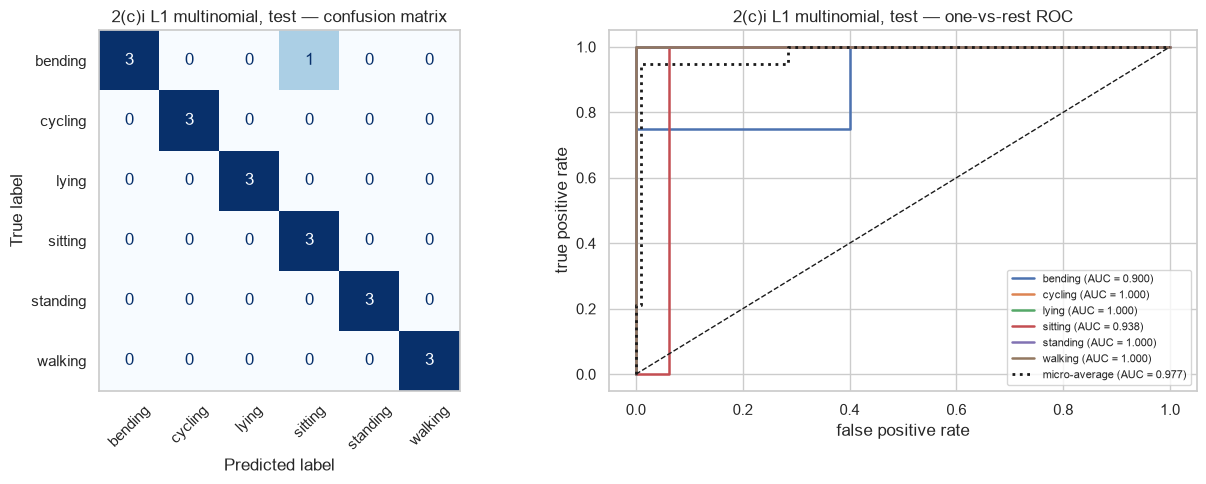

2(c)i L1 multinomial, test: accuracy = 0.9474, macro one-vs-rest AUC = 0.9729


In [31]:
def plot_multiclass_results(y_true, y_pred, proba, classes, title):
    # K x K confusion matrix plus the one-vs-rest ROC curves.
    fig, axes = plt.subplots(1, 2, figsize=(13, 5))
    ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred, labels=classes),
                           display_labels=classes).plot(ax=axes[0], cmap="Blues",
                                                        colorbar=False, xticks_rotation=45)
    axes[0].set_title(f"{title} — confusion matrix")
    axes[0].grid(False)

    y_bin = label_binarize(y_true, classes=classes)
    for i, cls in enumerate(classes):
        if y_bin[:, i].sum() == 0:
            continue
        fpr, tpr, _ = roc_curve(y_bin[:, i], proba[:, i])
        axes[1].plot(fpr, tpr, lw=1.8, label=f"{cls} (AUC = {auc(fpr, tpr):.3f})")
    fpr_micro, tpr_micro, _ = roc_curve(y_bin.ravel(), proba.ravel())
    axes[1].plot(fpr_micro, tpr_micro, "k:", lw=2,
                 label=f"micro-average (AUC = {auc(fpr_micro, tpr_micro):.3f})")
    axes[1].plot([0, 1], [0, 1], "k--", lw=1)
    axes[1].set_xlabel("false positive rate")
    axes[1].set_ylabel("true positive rate")
    axes[1].set_title(f"{title} — one-vs-rest ROC")
    axes[1].legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()

    macro = roc_auc_score(y_bin, proba, average="macro", multi_class="ovr")
    print(f"{title}: accuracy = {(y_true == y_pred).mean():.4f}, macro one-vs-rest AUC = {macro:.4f}")
    return macro


multi_macro_auc = plot_multiclass_results(y_multi_test, multi_pred, multi_proba,
                                          list(multi_model.classes_),
                                          "2(c)i L1 multinomial, test")

The L1 multinomial model makes 1 mistake on the 19 test instances, so its test error is 0.053. The mistake is a bending instance that is predicted as sitting.

#### 2(c)ii Naïve Bayes with Gaussian and multinomial priors

To compare fairly with 2(c)i, both models are tuned over the same values of $l$.
Gaussian naïve Bayes models each feature within each class with a normal distribution, and it uses the raw features.
Multinomial naïve Bayes needs features that are not negative, like counts.
So we rescale the features to the range 0 to 1 with a `MinMaxScaler` fit on the training set. Test values outside this range are clipped.

In [32]:
def make_nb(kind):
    return GaussianNB() if kind == "gaussian" else make_pipeline(MinMaxScaler(clip=True), MultinomialNB())


nb_records = []
for l in L_GRID:
    X_tr, _, _ = split_matrices(l)
    for kind in ("gaussian", "multinomial"):
        score = cross_val_score(make_nb(kind), X_tr, y_multi_train, cv=cv, scoring="accuracy").mean()
        nb_records.append({"l": l, "prior": kind, "cv_accuracy": score})

nb_results = pd.DataFrame(nb_records)
nb_best = nb_results.sort_values(["cv_accuracy", "l"], ascending=[False, True]) \
                    .groupby("prior", as_index=False).first()
print(nb_best.round(4).to_string(index=False))
nb_results.pivot(index="l", columns="prior", values="cv_accuracy").round(3)

      prior  l  cv_accuracy
   gaussian  1       0.8253
multinomial  5       0.7670


prior,gaussian,multinomial
l,,
1,0.825,0.709
2,0.784,0.752
3,0.680,0.708
4,0.723,0.710
5,0.708,0.767
6,0.648,0.752
7,0.652,0.752
8,0.652,0.724
9,0.623,0.752


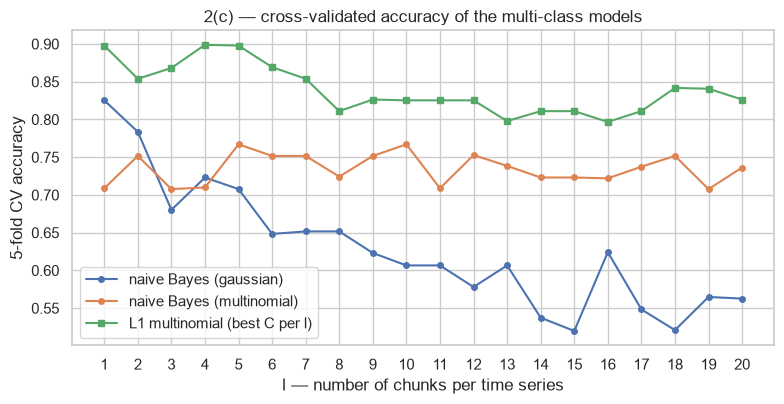

In [33]:
fig, ax = plt.subplots(figsize=(8, 4.2))
for kind, grp in nb_results.groupby("prior"):
    ax.plot(grp["l"], grp["cv_accuracy"], marker="o", ms=4, label=f"naive Bayes ({kind})")
ax.plot(multi_results.groupby("l")["cv_accuracy"].max(), marker="s", ms=4,
        label="L1 multinomial (best C per l)")
ax.set_xticks(L_GRID)
ax.set_xlabel("l — number of chunks per time series")
ax.set_ylabel("5-fold CV accuracy")
ax.set_title("2(c) — cross-validated accuracy of the multi-class models")
ax.legend()
plt.tight_layout()
plt.show()

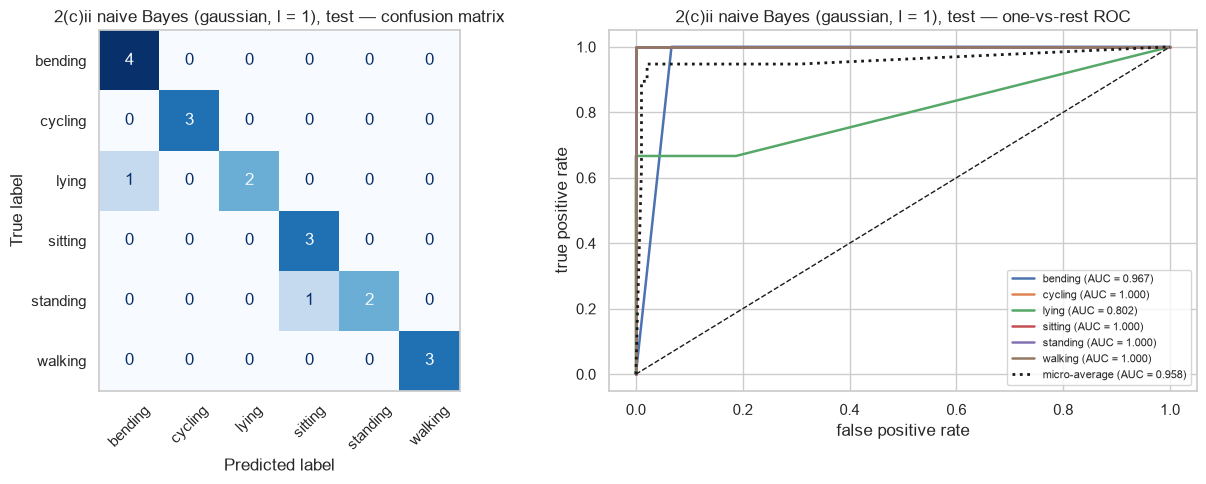

2(c)ii naive Bayes (gaussian, l = 1), test: accuracy = 0.8947, macro one-vs-rest AUC = 0.9615


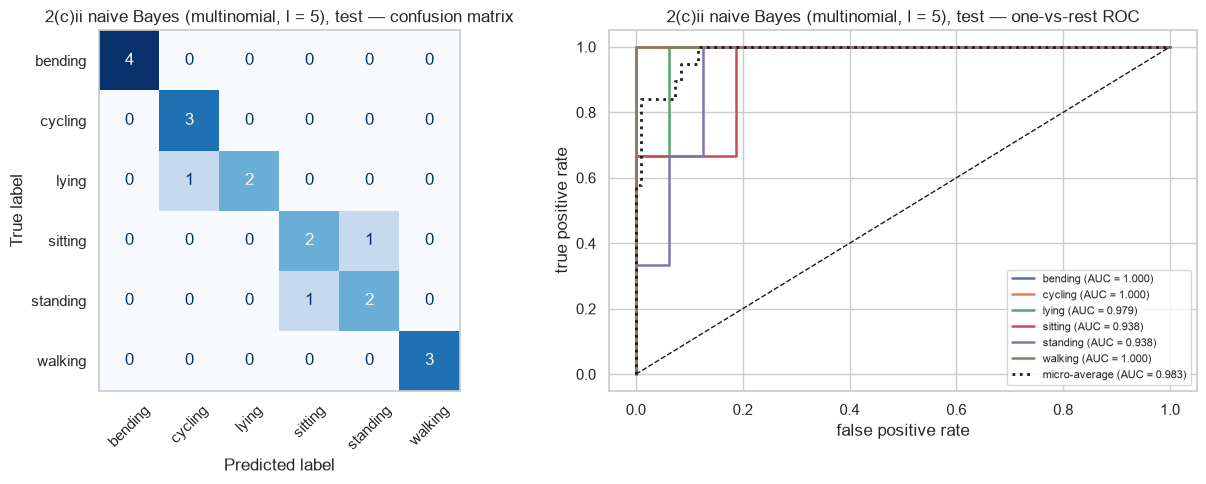

2(c)ii naive Bayes (multinomial, l = 5), test: accuracy = 0.8421, macro one-vs-rest AUC = 0.9757


In [34]:
nb_summary = []
for _, row in nb_best.iterrows():
    kind, l = row["prior"], int(row["l"])
    X_tr, X_te, _ = split_matrices(l)
    model = make_nb(kind).fit(X_tr, y_multi_train)
    pred, proba = model.predict(X_te), model.predict_proba(X_te)
    classes = list(model.classes_ if hasattr(model, "classes_") else model[-1].classes_)
    macro = plot_multiclass_results(y_multi_test, pred, proba, classes,
                                    f"2(c)ii naive Bayes ({kind}, l = {l}), test")
    nb_summary.append({"model": f"naive Bayes ({kind})", "l": l,
                       "CV accuracy": row["cv_accuracy"],
                       "test accuracy": (pred == y_multi_test).mean(),
                       "test error": 1 - (pred == y_multi_test).mean(),
                       "macro AUC": macro})

#### 2(c)iii Which method is better for multi-class classification here?

In [35]:
comparison = pd.DataFrame([{
    "model": "L1 multinomial regression", "l": BEST_L_MULTI,
    "CV accuracy": best_multi["cv_accuracy"], "test accuracy": multi_test_acc,
    "test error": 1 - multi_test_acc, "macro AUC": multi_macro_auc,
}] + nb_summary).set_index("model")
comparison.round(4)

,l,CV accuracy,test accuracy,test error,macro AUC
model,,,,,
L1 multinomial regression,4,0.8989,0.9474,0.0526,0.9729
naive Bayes (gaussian),1,0.8253,0.8947,0.1053,0.9615
naive Bayes (multinomial),5,0.7670,0.8421,0.1579,0.9757


In [36]:
# Evidence for the discussion below.
f20 = FEATURES[20]
neighbour_corr = {}
for stat in ("mean", "max", "std"):
    for s in (1, 6):
        corrs = [f20[f"{stat}{s}_{k}"].corr(f20[f"{stat}{s}_{k + 1}"]) for k in range(1, 20)]
        neighbour_corr[f"{stat}{s}"] = np.median(corrs)
print("median correlation between neighbouring parts at l = 20, all 88 instances:")
print(pd.Series(neighbour_corr).round(3).to_string())

print()
print("share of cross-validated predictions whose top probability is above 0.999:")
for l in (1, 20):
    X_tr, _, _ = split_matrices(l)
    for kind in ("gaussian", "multinomial"):
        proba = cross_val_predict(make_nb(kind), X_tr, y_multi_train, cv=cv, method="predict_proba")
        print(f"  l = {l:2d}, naive Bayes ({kind}): {np.mean(proba.max(axis=1) > 0.999):.2f}")

median correlation between neighbouring parts at l = 20, all 88 instances:
mean1    0.970
mean6    0.939
max1     0.919
max6     0.836
std1     0.841
std6     0.826

share of cross-validated predictions whose top probability is above 0.999:
  l =  1, naive Bayes (gaussian): 0.93
  l =  1, naive Bayes (multinomial): 0.00
  l = 20, naive Bayes (gaussian): 1.00
  l = 20, naive Bayes (multinomial): 0.45


**Answer.** The L1-penalized multinomial regression is the better method here.

It has the best cross-validation accuracy: 0.899, compared with 0.825 for Gaussian naïve Bayes and 0.767 for multinomial naïve Bayes.
These are the best scores over all the settings we tried, so all three are a little optimistic, and the regression a bit more, because it had more settings to try.
It is also the best on the test set. It makes 1 mistake out of 19, so its test accuracy is 0.947.
Gaussian naïve Bayes makes 2 mistakes and multinomial naïve Bayes makes 3.

The macro AUCs, 0.973, 0.962 and 0.976, cannot separate the models.
Each class has only 3 or 4 test instances, so a single pair of instances in the wrong order changes the macro AUC by about 0.003.
The gaps between the three models are between 0.003 and 0.014, which is only a few such pairs.

The plot of accuracy against $l$ also shows that the regression is more stable. As $l$ grows, the number of features goes from 42 to 840.
Gaussian naïve Bayes drops from 0.825 at $l = 1$ to about 0.56 at $l = 20$. The regression stays between about 0.80 and 0.90 for every $l$.
This comparison favors the regression a little, because its curve uses the best of five values of $C$ at each $l$, while we did not tune naïve Bayes.

Naïve Bayes assumes that the features are independent within each class, but our features are strongly related.
Min, Q1, median, mean, Q3 and max of the same part all come from the same samples, as 1(c)iv showed.
Nearby parts of the same series are also similar: at $l = 20$, the median correlation between neighbouring parts is between 0.83 and 0.97 in the output above.
Naïve Bayes treats all of these as separate pieces of evidence, so it counts the same evidence many times. This makes its probabilities far too confident.
The output above shows that 93% of the Gaussian model's cross-validated predictions at $l = 1$ have a top probability above 0.999, and 100% at $l = 20$,
even though its accuracy there is only 0.825 and 0.563. More parts means more double counting.
Logistic regression does not have this problem. It fits all the coefficients together, so two copies of the same information share one effect.

Cross-validation did not pick a sparse model here. It picked the weakest penalty in the grid, $C = 100$, and 958 of the 1008 coefficients are not zero.
So at the chosen $l$, the gain over naïve Bayes does not come from the penalty removing features.

The Gaussian version of naïve Bayes is better at $l = 1$, 2 and 4.
From $l = 5$ on, the multinomial version is better at every $l$, with accuracy between about 0.71 and 0.77.
Its probabilities are also less extreme. At $l = 1$, none of its predictions has a top probability above 0.999.
A likely reason is that each feature is scaled to the range 0 to 1, so one feature can only change the score by a limited amount.
In the Gaussian model, one feature with a very small variance inside a class can change the score by a huge amount.
Still, neither version beats the regression.

The regression's one mistake is a `bending` instance predicted as `sitting`.
Gaussian naïve Bayes predicts a `lying` instance as `bending` and a `standing` instance as `sitting`.
Multinomial naïve Bayes swaps `sitting` and `standing` and predicts a `lying` instance as `cycling`.
Every mistake starts from one of the still activities, whose variance series look alike, as the table in 2(a)i showed.
All `cycling` and `walking` instances are classified correctly by all three models.

## 3. ISLR 4.8.3

**Problem.** There is one predictor, so $p = 1$. The observations in class $k$ come from a normal distribution $N(\mu_k, \sigma_k^2)$, and each class has its own variance $\sigma_k^2$.
Show that the Bayes classifier is not linear, and that it is in fact quadratic.

**Solution.** The density of $X$ in class $k$ is

$$f_k(x) = \frac{1}{\sqrt{2\pi}\,\sigma_k}\exp\left(-\frac{1}{2\sigma_k^2}(x-\mu_k)^2\right)$$

By Bayes' theorem, the probability of class $k$ given $X = x$ is

$$p_k(x) = \frac{\pi_k f_k(x)}{\sum_{l=1}^{K} \pi_l f_l(x)}$$

The Bayes classifier picks the class with the largest $p_k(x)$. The denominator is the same for every class, and the log is an increasing function.
So we can instead pick the class with the largest

$$\delta_k(x) = \log\big(\pi_k f_k(x)\big) = -\frac{(x-\mu_k)^2}{2\sigma_k^2} - \log \sigma_k + \log \pi_k - \frac{1}{2}\log 2\pi$$

The last term is the same for every class, so we drop it. Expanding the square gives

$$\delta_k(x) = -\frac{1}{2\sigma_k^2}x^2 + \frac{\mu_k}{\sigma_k^2}x - \frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k$$

This is a quadratic function of $x$. It has the form $a_k x^2 + b_k x + c_k$ with

$$a_k = -\frac{1}{2\sigma_k^2}, \qquad b_k = \frac{\mu_k}{\sigma_k^2}, \qquad c_k = -\frac{\mu_k^2}{2\sigma_k^2} - \log\sigma_k + \log\pi_k$$

The boundary between class $k$ and class $m$ is where $\delta_k(x) = \delta_m(x)$:

$$(a_k - a_m)x^2 + (b_k - b_m)x + (c_k - c_m) = 0, \qquad a_k - a_m = \frac{1}{2}\left(\frac{1}{\sigma_m^2} - \frac{1}{\sigma_k^2}\right)$$

When the two variances are different, $a_k - a_m$ is not zero, so this is a real quadratic equation.
It can have two roots, and the region for one class does not have to be a single interval.
So the Bayes classifier is quadratic, not linear. This is why the method is called quadratic discriminant analysis.

**Compare with LDA.** If all classes had the same variance $\sigma^2$, then $a_k = -\frac{1}{2\sigma^2}$ would be the same for every class.
The $x^2$ terms would cancel when we compare two classes, and we would get the linear LDA function

$$\delta_k(x) = \frac{\mu_k}{\sigma^2}x - \frac{\mu_k^2}{2\sigma^2} + \log\pi_k$$

So the quadratic term comes only from letting each class have its own variance.

## 4. ISLR 4.8.7

**Problem.** We want to predict whether a company will issue a dividend this year based on $X$, last year's percent profit.
For companies that issued a dividend, the mean of $X$ was 10. For companies that did not, the mean was 0.
The variance of $X$ was 36 in both groups, and 80% of companies issued a dividend.
Assume $X$ is normal in each group. Find the probability that a company with $X = 4$ will issue a dividend.

**Solution.** Let $Y = 1$ mean the company issues a dividend. We have

$$\pi_1 = 0.8, \quad \pi_0 = 0.2, \quad \mu_1 = 10, \quad \mu_0 = 0, \quad \sigma^2 = 36$$

Both groups have the same variance, so we use Bayes' theorem with normal densities.
The factor $\frac{1}{\sqrt{2\pi}\,\sigma}$ is the same in every term, so it cancels:

$$P(Y = 1 \mid X = x) = \frac{\pi_1 \exp\left(-\frac{(x-\mu_1)^2}{2\sigma^2}\right)}{\pi_1 \exp\left(-\frac{(x-\mu_1)^2}{2\sigma^2}\right) + \pi_0 \exp\left(-\frac{(x-\mu_0)^2}{2\sigma^2}\right)}$$

Now put in $x = 4$, so $2\sigma^2 = 72$:

$$\pi_1 \exp\left(-\frac{(4-10)^2}{72}\right) = 0.8\,e^{-0.5} = 0.8 \times 0.606531 = 0.485225$$

$$\pi_0 \exp\left(-\frac{(4-0)^2}{72}\right) = 0.2\,e^{-0.222222} = 0.2 \times 0.800737 = 0.160147$$

$$P(Y = 1 \mid X = 4) = \frac{0.485225}{0.485225 + 0.160147} = \frac{0.485225}{0.645372} = 0.7519$$

**Answer: about 0.752. There is a 75.2% chance that the company issues a dividend.**

Check: $X = 4$ is a little closer to 0 than to 10, so the data alone slightly favor no dividend.
But the 80% prior is strong, so the final probability only drops from 0.80 to 0.75.

In [37]:
# Numerical check of 4.8.7.
pi1, pi0, mu1, mu0, sigma2 = 0.8, 0.2, 10.0, 0.0, 36.0
x = 4.0
num = pi1 * np.exp(-((x - mu1) ** 2) / (2 * sigma2))
den = num + pi0 * np.exp(-((x - mu0) ** 2) / (2 * sigma2))
print(f"numerator   = {num:.6f}")
print(f"denominator = {den:.6f}")
print(f"P(dividend | X = 4) = {num / den:.4f}")

numerator   = 0.485225
denominator = 0.645372
P(dividend | X = 4) = 0.7519
